---

# Sepakat: Optimasi Muatan Kapal

*Analisis eksperimen local search pada penataan kendaraan, kapasitas berat, dan pendapatan pengiriman.*

---

## G09 - Sepakat

- Riantama Putra (18224061)
- Tiara Kusuma Wardhani (18224059)
- Levina Nathania Bunardi (18224057)

---

## Daftar Isi

1. [Introduction](#1)
2. [Initialization](#2)
3. [Data dan Protokol](#3)
4. [Tabel Eksperimen](#4)
5. [Hill-Climbing](#5)
6. [Simulated Annealing](#6)
7. [Genetic Algorithm](#7)
8. [Perbandingan Algoritma](#8)
9. [State Terbaik](#9)
10. [Multi-kapal dan ETA](#10)
11. [Batas Atas dan Optimum Eksak](#11)
12. [Kesimpulan dan Referensi](#12)

---

# Introduction <a name="1"></a>

---

## Overview

*Notebook ini membaca hasil resmi dari `output/experiments/` tanpa mengulang pencarian. Semua angka, tabel, dan simpulan kuantitatif dihitung dari JSON saat notebook dijalankan; sel analisis berhenti jika artefak belum lengkap.*

*Hill-Climbing memilih tetangga yang memperbaiki objective, dengan varian stochastic, sideways, dan random restart. Simulated Annealing dapat menerima penurunan dengan peluang `exp(delta/T)`. Genetic Algorithm menggunakan seleksi roulette, crossover satu titik, mutasi, dan elitisme pada populasi.*

*Objective pendapatan dikurangi penalti pelanggaran. State awal tetap acak dan boleh tidak feasible; state akhir merupakan incumbent feasible terbaik yang tercatat, termasuk baseline kapal kosong bila belum ditemukan kandidat feasible. Nilai maksimum populasi atau state berjalan tidak selalu sama dengan incumbent ini. Batas atas relaksasi bukan bukti optimum geometris.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Analisis dan algoritma berjalan pada CPU, tanpa GPU atau unduhan otomatis. Dari root repository, siapkan lingkungan dengan `python -m pip install -r requirements.txt`, lalu jalankan `python src/experiments.py` untuk menghasilkan seluruh eksperimen resmi. Notebook dapat dibuka dari root atau direktori `notebooks/`.

Pembangun `python src/scripts/build_notebook.py` menghasilkan notebook bersih. Opsi `--execute` menjalankannya melalui kernel Python lokal setelah artefak lengkap; eksekusi notebook tidak memasang paket melalui jaringan.

## Import Libraries

Sel Libraries memusatkan seluruh impor dan menambahkan `src/` ke jalur modul lokal sebelum memuat kode proyek.

In [1]:
import math
import random
import sys
from collections import Counter
from io import BytesIO
from pathlib import Path
from statistics import mean, stdev

import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from IPython.display import Image, Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'experiments.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Buka notebook dari dalam repository Sepakat.')
sys.path.insert(0, str(ROOT / 'src'))
from config import DATA_DIR, EXPERIMENTS_DIR
from core.bounds import brute_force, upper_bound
from core.eta_objective import eta_problem, shipping_fee_total, urgency_weight
from core.problem import load_problem
from core.state import State
from experiments import comparison_groups, load_results, machine_info, planned_runs, summary_sections
from visualization.plots import plot_objective, plot_run, plot_summary
from visualization.state_view import draw_state

## Seed Everything

Seed analisis ditetapkan agar pemilihan tambahan tetap dapat direproduksi. Seed pencarian tetap mengikuti masing-masing JSON dan tidak diubah oleh notebook.

In [2]:
def seed_everything(seed=42):
    random.seed(seed)

seed_everything(42)

## Settings

Lokasi data dan hasil memakai konfigurasi proyek. Tampilan grafik memakai ukuran terbaca dan palet yang konsisten; notebook tidak menulis ulang hasil pencarian.

In [3]:
class Settings:
    SEED = 42
    DATA_DIR = DATA_DIR
    OUT = EXPERIMENTS_DIR
    EXPECTED_RUNS = 39
    EXPECTED_REQUIRED = 24
    EXACT_MAX_NODES = 5_000_000
    COLORS = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']

CFG = Settings()
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.2,
                     'axes.prop_cycle': plt.cycler(color=CFG.COLORS), 'figure.dpi': 100})
print('Mesin analisis saat ini:', machine_info())
print('Durasi dalam JSON adalah durasi pencarian, bukan waktu menggambar atau analisis.')
print('Identitas mesin pembuat JSON tidak disimpulkan dari mesin analisis ini.')

Mesin analisis saat ini: Linux-7.2.9-arch1-1-x86_64-with-glibc2.44 | CPU x86_64 (22 thread) | Python 3.14.7
Durasi dalam JSON adalah durasi pencarian, bukan waktu menggambar atau analisis.
Identitas mesin pembuat JSON tidak disimpulkan dari mesin analisis ini.


## Load Dataset

Rencana resmi menentukan berkas yang dibaca, bukan pencarian glob yang dapat mencampurkan run manual atau quick. Setiap grup GA harus memuat sembilan eksekusi tersendiri, termasuk kontrol yang dicatat terpisah.

In [4]:
plan = planned_runs()
assert len(plan) == CFG.EXPECTED_RUNS
assert sum(run.required for run in plan) == CFG.EXPECTED_REQUIRED
assert all(len(run.groups) == 1 for run in plan)
assert len({run.path(CFG.OUT) for run in plan}) == len(plan)
for group in ('ga_iter', 'ga_pop'):
    assert sum(run.groups[0] == group for run in plan) == 9
missing = []
for run in plan:
    path = run.path(CFG.OUT)
    for artifact in [path, *(path.with_name(path.stem + suffix) for suffix in ('_initial.png', '_final.png', '_plot.png'))]:
        if not artifact.is_file():
            missing.append(str(artifact.relative_to(ROOT)))
if missing:
    raise FileNotFoundError('Artefak belum lengkap. Jalankan python src/experiments.py.\n' + '\n'.join(missing))
pairs = load_results(plan, CFG.OUT)
assert len(pairs) == len(plan)
problems = {run.instance: load_problem(run.instance) for run in plan}

def of(group, algorithm=None):
    return [(run, result) for run, result in pairs
            if run.groups[0] == group and (algorithm is None or run.algo == algorithm)]

def table(headers, rows):
    def cell(value):
        return str(value).replace('|', '/')
    display(Markdown(' | '.join(headers) + '\n' + ' | '.join(['---'] * len(headers)) + '\n' +
                     '\n'.join(' | '.join(cell(v) for v in row) for row in rows)))

def insights(text):
    display(Markdown('#### Insights\n\n> ' + text))

def show(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=110)
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

print(f'{len(pairs)} run lengkap; {sum(run.required for run in plan)} wajib.')

39 run lengkap; 24 wajib.


---

# Data dan Protokol <a name="3"></a>

---

Setiap state awal dan akhir direkonstruksi dari penempatan kendaraan pada instance yang tepat. Pemeriksaan ini menghitung ulang objective, feasibility, fee, dan batas atas, serta memastikan berkas PNG dapat dibaca sebelum analisis dilanjutkan.

In [5]:
audit = []
for run, result in pairs:
    original = problems[run.instance]
    problem = eta_problem(original) if run.objective == 'eta' else original
    assert result['algorithm'] == run.algo and result['seed'] == run.seed
    assert result['instance'] == problem.name
    assert result.get('extra', {}).get('objective', 'fee') == run.objective
    for key, value in run.params.items():
        assert result['params'][key] == value
    for key in ('initial', 'final'):
        state = State.from_dict(problem, result[key + '_state'])
        evaluation = state.evaluate()
        assert math.isclose(evaluation.objective, result[key + '_objective'], abs_tol=1e-7)
        if key == 'final':
            assert evaluation.is_feasible and result['is_feasible']
            assert math.isclose(evaluation.total_fee, result['total_fee'], abs_tol=1e-7)
            if run.objective == 'eta':
                assert math.isclose(shipping_fee_total(original, state.positions),
                                    result['extra']['shipping_fee_total'], abs_tol=1e-7)
    bound = upper_bound(problem)
    assert math.isclose(bound, result['upper_bound'], abs_tol=1e-7)
    assert result['final_objective'] <= bound + 1e-7
    if bound:
        assert math.isclose((bound - result['final_objective']) / bound, result['gap_ub'], abs_tol=1e-7)
    path = run.path(CFG.OUT)
    for suffix in ('_initial.png', '_final.png', '_plot.png'):
        assert plt.imread(path.with_name(path.stem + suffix)).size > 0
    audit.append([run.groups[0], run.algo, run.seed, result['final_objective'],
                  result['extra'].get('empty_baseline_used', False)])
table(['Instance', 'Kapal', 'Kendaraan', 'Luas geladak', 'Kapasitas berat'],
      [[p.name, len(p.ships), len(p.vehicles), sum(s.area for s in p.ships),
        sum(s.max_capacity for s in p.ships)] for p in problems.values()])
table(['Grup', 'Run'], sorted(Counter(row[0] for row in audit).items()))
insights(f'Seluruh {len(audit)} state akhir lolos evaluasi ulang; '
         f'{sum(row[4] for row in audit)} run memakai baseline kosong. '
         'Feasibility sendiri tidak membuktikan pencarian menemukan muatan yang berguna.')

Instance | Kapal | Kendaraan | Luas geladak | Kapasitas berat
--- | --- | --- | --- | ---
main | 1 | 30 | 200 | 131
multi | 3 | 40 | 248 | 166

Grup | Run
--- | ---
eta | 3
ga_iter | 9
ga_pop | 9
hc | 3
hc_variants | 9
multi | 3
sa | 3

#### Insights

> Seluruh 39 state akhir lolos evaluasi ulang; 0 run memakai baseline kosong. Feasibility sendiri tidak membuktikan pencarian menemukan muatan yang berguna.

#### Insights

> Tiap sweep GA memiliki run tersendiri. Kontrol dengan seed dan parameter identik bukan sampel acak baru untuk perbandingan antar-algoritma; fungsi `comparison_groups` menghindari penghitungan ganda.

---

# Tabel Eksperimen <a name="4"></a>

---

Tabel resmi memakai helper yang sama dengan runner agar jumlah iterasi, parameter, durasi, restart, sideways, stuck, dan hasil setiap seed tetap konsisten. Nilai bobot ETA dan pendapatan asli ditampilkan terpisah.

In [6]:
display(Markdown('\n'.join(summary_sections(pairs))))


### 4.1 Hill-Climbing - Steepest Ascent

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | Evals | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 982 | 982 | True | 5.1% | 16 | 208453 | 1.251 |
| 2 | 2 | -50553 | 978 | 978 | True | 5.5% | 20 | 258032 | 1.549 |
| 3 | 3 | -28402 | 902 | 902 | True | 12.9% | 17 | 221239 | 1.327 |
| **mean ± std** |  |  | 954.0 ± 45.1 | 954.0 ± 45.1 |  |  |  |  | 1.376 ± 0.155 |

### 4.2 Hill-Climbing - Stochastic (Bonus 2)

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | Evals | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 778 | 778 | True | 24.8% | 36486 | 36487 | 0.405 |
| 2 | 2 | -50553 | 876 | 876 | True | 15.4% | 32510 | 32511 | 0.365 |
| 3 | 3 | -28402 | 771 | 771 | True | 25.5% | 24504 | 24505 | 0.277 |
| **mean ± std** |  |  | 808.3 ± 58.7 | 808.3 ± 58.7 |  |  |  |  | 0.349 ± 0.065 |

### 4.3 Hill-Climbing - Sideways Move

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | #Sideways | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 982 | 982 | True | 5.1% | 116 | 100 | 10.700 |
| 2 | 2 | -50553 | 978 | 978 | True | 5.5% | 120 | 100 | 10.127 |
| 3 | 3 | -28402 | 960 | 960 | True | 7.2% | 118 | 100 | 10.743 |
| **mean ± std** |  |  | 973.3 ± 11.7 | 973.3 ± 11.7 |  |  |  |  | 10.523 ± 0.344 |

### 4.4 Hill-Climbing - Random Restart

| Run | Seed | Obj akhir | Fee | Feasible | Gap UB | #Restart | Iterasi per restart | Durasi (s) |
|---|---|---|---|---|---|---|---|---|
| 1 | 1 | 982 | 982 | True | 5.1% | 10 | 16, 14, 20, 17, 16, 15, 17, 17, 23, 16, 22 | 16.864 |
| 2 | 2 | 993 | 993 | True | 4.1% | 10 | 20, 18, 17, 13, 22, 14, 15, 22, 18, 18, 18 | 16.876 |
| 3 | 3 | 946 | 946 | True | 8.6% | 10 | 17, 23, 17, 16, 20, 16, 20, 19, 17, 18, 14 | 16.493 |
| **mean ± std** |  | 973.7 ± 24.6 | 973.7 ± 24.6 |  |  |  |  | 16.745 ± 0.218 |

### 4.5 Simulated Annealing

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | #Stuck | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 964 | 964 | True | 6.9% | 100000 | 4 | 8.435 |
| 2 | 2 | -50553 | 973 | 973 | True | 6.0% | 100000 | 1 | 8.488 |
| 3 | 3 | -28402 | 962 | 962 | True | 7.1% | 100000 | 3 | 10.121 |
| **mean ± std** |  |  | 966.3 ± 5.9 | 966.3 ± 5.9 |  |  |  |  | 9.015 ± 0.959 |

### 4.6 GA - kontrol populasi, variasi iterasi

| Iterasi | Run | Seed | Obj akhir (best) | Fee | Feasible | Gap UB | Durasi (s) |
|---|---|---|---|---|---|---|---|
| 300 | 1-3 | 1,2,3 | 721 / 863 / 858 (mean 814.0 ± 80.6) | 721 / 863 / 858 | True / True / True | 30.3% / 16.6% / 17.1% | 0.284 / 0.250 / 0.271 |
| 1000 | 1-3 | 1,2,3 | 780 / 908 / 865 (mean 851.0 ± 65.1) | 780 / 908 / 865 | True / True / True | 24.6% / 12.3% / 16.4% | 0.802 / 0.758 / 0.856 |
| 3000 | 1-3 | 1,2,3 | 803 / 927 / 876 (mean 868.7 ± 62.3) | 803 / 927 / 876 | True / True / True | 22.4% / 10.4% / 15.4% | 2.266 / 2.292 / 2.685 |

### 4.7 GA - kontrol iterasi, variasi populasi

| Populasi | Run | Seed | Obj akhir (best) | Fee | Feasible | Gap UB | Durasi (s) |
|---|---|---|---|---|---|---|---|
| 50 | 1-3 | 1,2,3 | 749 / 778 / 804 (mean 777.0 ± 27.5) | 749 / 778 / 804 | True / True / True | 27.6% / 24.8% / 22.3% | 0.329 / 0.341 / 0.343 |
| 100 | 1-3 | 1,2,3 | 780 / 908 / 865 (mean 851.0 ± 65.1) | 780 / 908 / 865 | True / True / True | 24.6% / 12.3% / 16.4% | 0.828 / 0.764 / 0.913 |
| 200 | 1-3 | 1,2,3 | 860 / 940 / 826 (mean 875.3 ± 58.5) | 860 / 940 / 826 | True / True / True | 16.9% / 9.2% / 20.2% | 1.981 / 2.054 / 1.971 |

### 4.8 Bonus 3 - multi-kapal

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Berat per kapal | Kendaraan per kapal | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -59430 | 1170 | 1170 | True | 11.2% | 70/80 / 51/54 / 30/32 | 10 / 6 / 5 | 4.060 |
| 2 | 2 | -37965 | 1072 | 1072 | True | 18.7% | 63/80 / 54/54 / 26/32 | 13 / 5 / 5 | 3.666 |
| 3 | 3 | -76448 | 1078 | 1078 | True | 18.2% | 78/80 / 48/54 / 15/32 | 4 / 8 / 7 | 4.156 |
| **mean ± std** |  |  | 1106.7 ± 54.9 | 1106.7 ± 54.9 |  |  |  |  | 3.961 ± 0.259 |

### 4.9 Ringkasan antar-algoritma (instance utama)

| Algoritma | Best | Mean ± std | Gap UB (mean) | Durasi mean (s) | Evals mean |
|---|---|---|---|---|---|
| steepest | 982 | 954.0 ± 45.1 | 7.8% | 1.376 | 229241 |
| sa | 973 | 966.3 ± 5.9 | 6.6% | 9.015 | 1136824 |
| stochastic | 876 | 808.3 ± 58.7 | 21.9% | 0.349 | 31168 |
| sideways | 982 | 973.3 ± 11.7 | 6.0% | 10.523 | 1454800 |
| random_restart | 993 | 973.7 ± 24.6 | 5.9% | 16.745 | 2534385 |
| ga (pop 200, iter 1000) - terbaik | 940 | 875.3 ± 58.5 | 15.4% | 2.002 | 198200 |

### 4.10 Bonus 1 - objective urgensi ETA

| Run | Seed | Obj awal | Obj akhir (bobot) | Fee asli | Feasible | Gap UB | Dimuat | Berat | Iterasi | #Stuck | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -30496.8 | 1293.3 | 984 | True | 3.9% | 16 | 130/131 | 100000 | 2 | 8.455 |
| 2 | 2 | -72463.9 | 1223.6 | 941 | True | 9.1% | 16 | 128/131 | 100000 | 5 | 8.808 |
| 3 | 3 | -40726.8 | 1228.8 | 941 | True | 8.7% | 15 | 124/131 | 100000 | 2 | 8.883 |
| **mean ± std** |  |  | 1248.6 ± 38.8 | 955.3 ± 24.8 |  |  |  |  |  |  | 8.715 ± 0.229 |

Bobot urgensi `fee * (1 + 1/(eta + 1))`, gap terhadap UB bobot. Perbandingan objective fee dan ETA pada seed yang sama ada di `summary_eta.md`.

#### Insights

> Mean dan simpangan baku merangkum tiga seed, bukan jaminan statistik untuk semua instance. Gap UB membandingkan solusi dengan relaksasi yang mengabaikan geometri dan tidak boleh disebut gap optimum eksak.

---

# Hill-Climbing <a name="5"></a>

---

Kurva menampilkan objective berjalan setiap seed untuk seluruh varian Hill-Climbing. Garis incumbent feasible ditampilkan jika berbeda, sehingga hasil akhir tetap dapat dijelaskan meskipun pencarian berhenti pada state berpenalti; nilai negatif tidak dipotong.

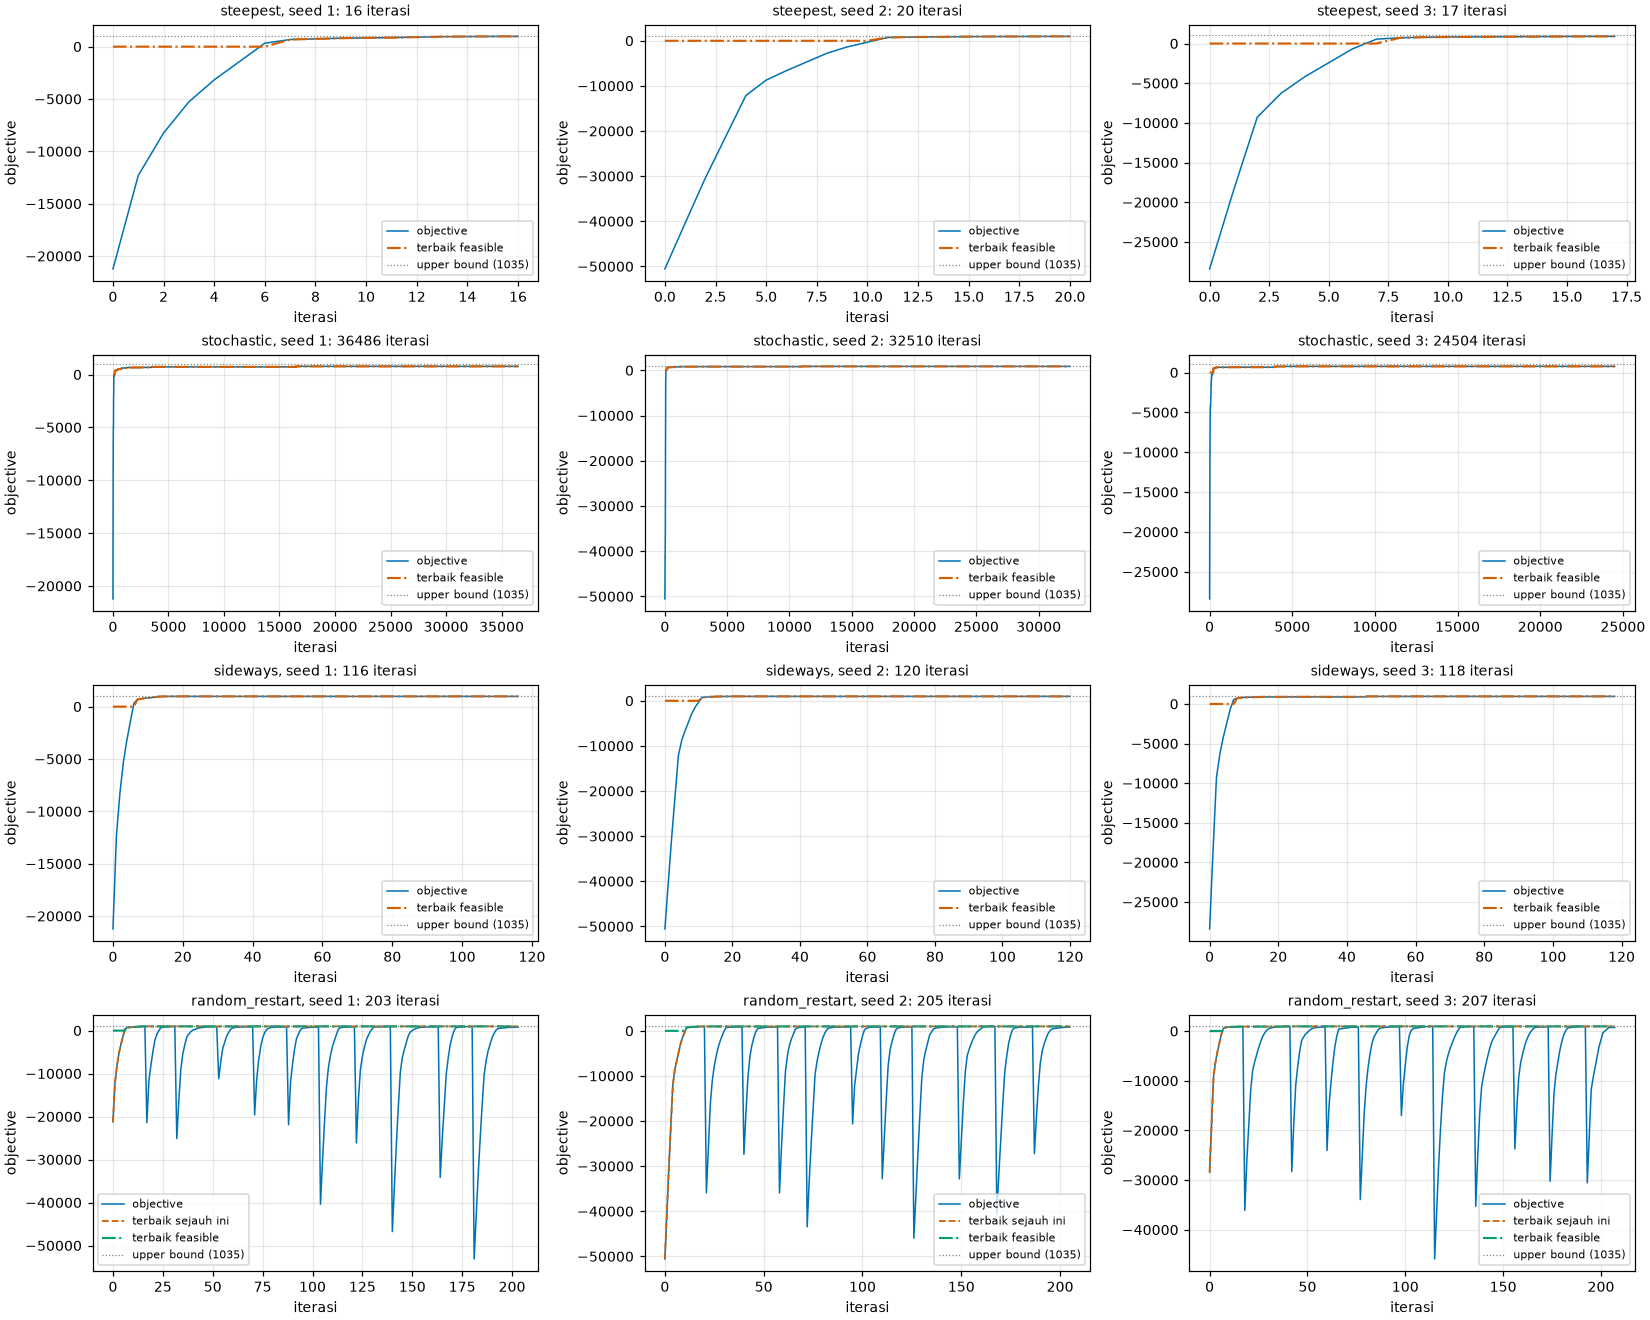

#### Insights

> Rata-rata objective akhir: random_restart = 973.67; sideways = 973.33; steepest = 954.00; stochastic = 808.33. Selisih ini merupakan pengamatan pada seed dan batas iterasi yang dicatat, bukan bukti satu varian selalu unggul.

In [7]:
hc_pairs = of('hc') + of('hc_variants')
fig = Figure(figsize=(15, 12), layout='constrained')
axes = fig.subplots(4, 3).flat
for ax, (run, result) in zip(axes, hc_pairs):
    plot_objective(ax, result)
    ax.set_title(f"{run.algo}, seed {run.seed}: {result['iterations']} iterasi", fontsize=9)
show(fig)
hc_means = {algo: mean(r['final_objective'] for run, r in hc_pairs if run.algo == algo)
            for algo in sorted({run.algo for run, r in hc_pairs})}
insights('Rata-rata objective akhir: ' + '; '.join(f'{a} = {v:.2f}' for a, v in hc_means.items()) +
         '. Selisih ini merupakan pengamatan pada seed dan batas iterasi yang dicatat, bukan bukti satu varian selalu unggul.')

#### Insights

> Steepest memeriksa banyak tetangga per langkah; satu iterasi tidak setara dengan satu evaluasi. Random restart mempunyai garis terbaik lintas percobaan, sedangkan sideways dan stochastic dibatasi parameter penghentian masing-masing pada tabel.

---

# Simulated Annealing <a name="6"></a>

---

SA dapat menurunkan objective berjalan ketika menerima langkah memburuk. Setiap panel peluang hanya menampilkan iterasi dengan delta negatif yang benar-benar tercatat; incumbent feasible tetap menjadi dasar hasil akhir.

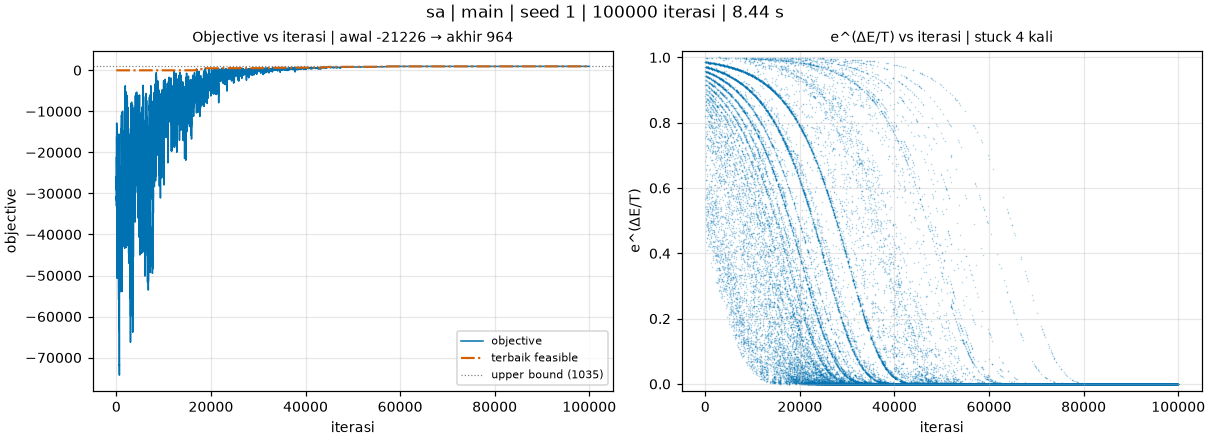

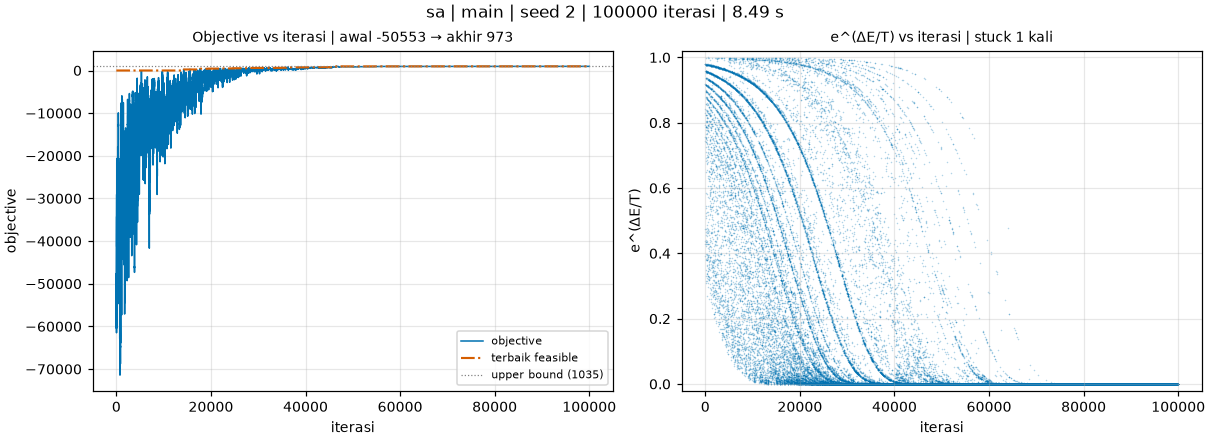

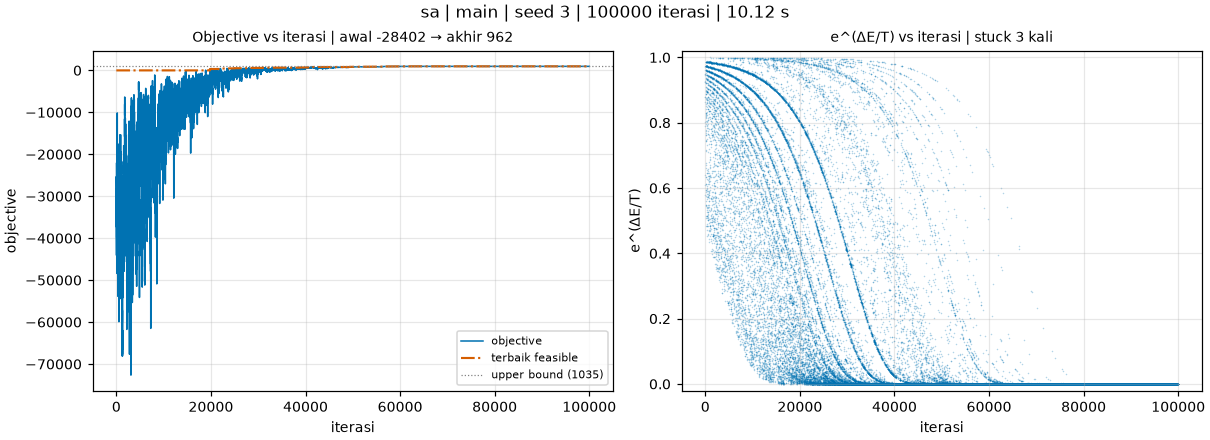

In [8]:
for run, result in of('sa'):
    show(plot_run(result))

In [9]:
sa_results = [result for run, result in of('sa')]
table(['Seed', 'Episode stuck teramati', 'Stagnation', 'Checkpoint', 'Evaluasi', 'Objective akhir'],
      [[r['seed'], r['extra'].get('stuck_count', 'tidak dicatat'),
        r['extra'].get('stagnation_count', 'tidak dicatat'), r['params'].get('stuck_window', 'lihat JSON'),
        r['evaluations'], r['final_objective']] for r in sa_results])
insights(f"Rata-rata episode stuck teramati = {mean(r['extra']['stuck_count'] for r in sa_results):.2f}; "
         f"rata-rata objective akhir = {mean(r['final_objective'] for r in sa_results):.2f}. "
         'Episode dihitung dari pemeriksaan tetangga pada checkpoint, bukan dari setiap langkah tanpa perbaikan. '
         'Checkpoint dengan tetangga membaik memutus rangkaian episode; stagnasi dicatat terpisah.')

Seed | Episode stuck teramati | Stagnation | Checkpoint | Evaluasi | Objective akhir
--- | --- | --- | --- | --- | ---
1 | 4 | 182 | 500 | 1190686 | 964.0
2 | 1 | 185 | 500 | 1148994 | 973.0
3 | 3 | 179 | 500 | 1070792 | 962.0

#### Insights

> Rata-rata episode stuck teramati = 2.67; rata-rata objective akhir = 966.33. Episode dihitung dari pemeriksaan tetangga pada checkpoint, bukan dari setiap langkah tanpa perbaikan. Checkpoint dengan tetangga membaik memutus rangkaian episode; stagnasi dicatat terpisah.

#### Insights

> Kurva peluang menggambarkan mekanisme penerimaan, bukan persentase keberhasilan pencarian. Episode stuck yang tidak teramati di antara checkpoint tidak dapat dihitung dari ringkasan ini; evaluasi pemeriksaan tetangga termasuk biaya pencarian.

---

# Genetic Algorithm <a name="7"></a>

---

Dua sweep dilakukan terpisah, masing-masing tiga konfigurasi dan tiga seed. Tiap panel memperlihatkan maksimum dan rata-rata populasi serta incumbent feasible jika berbeda; maksimum populasi yang belum feasible bukan solusi muatan yang dapat dikirim.

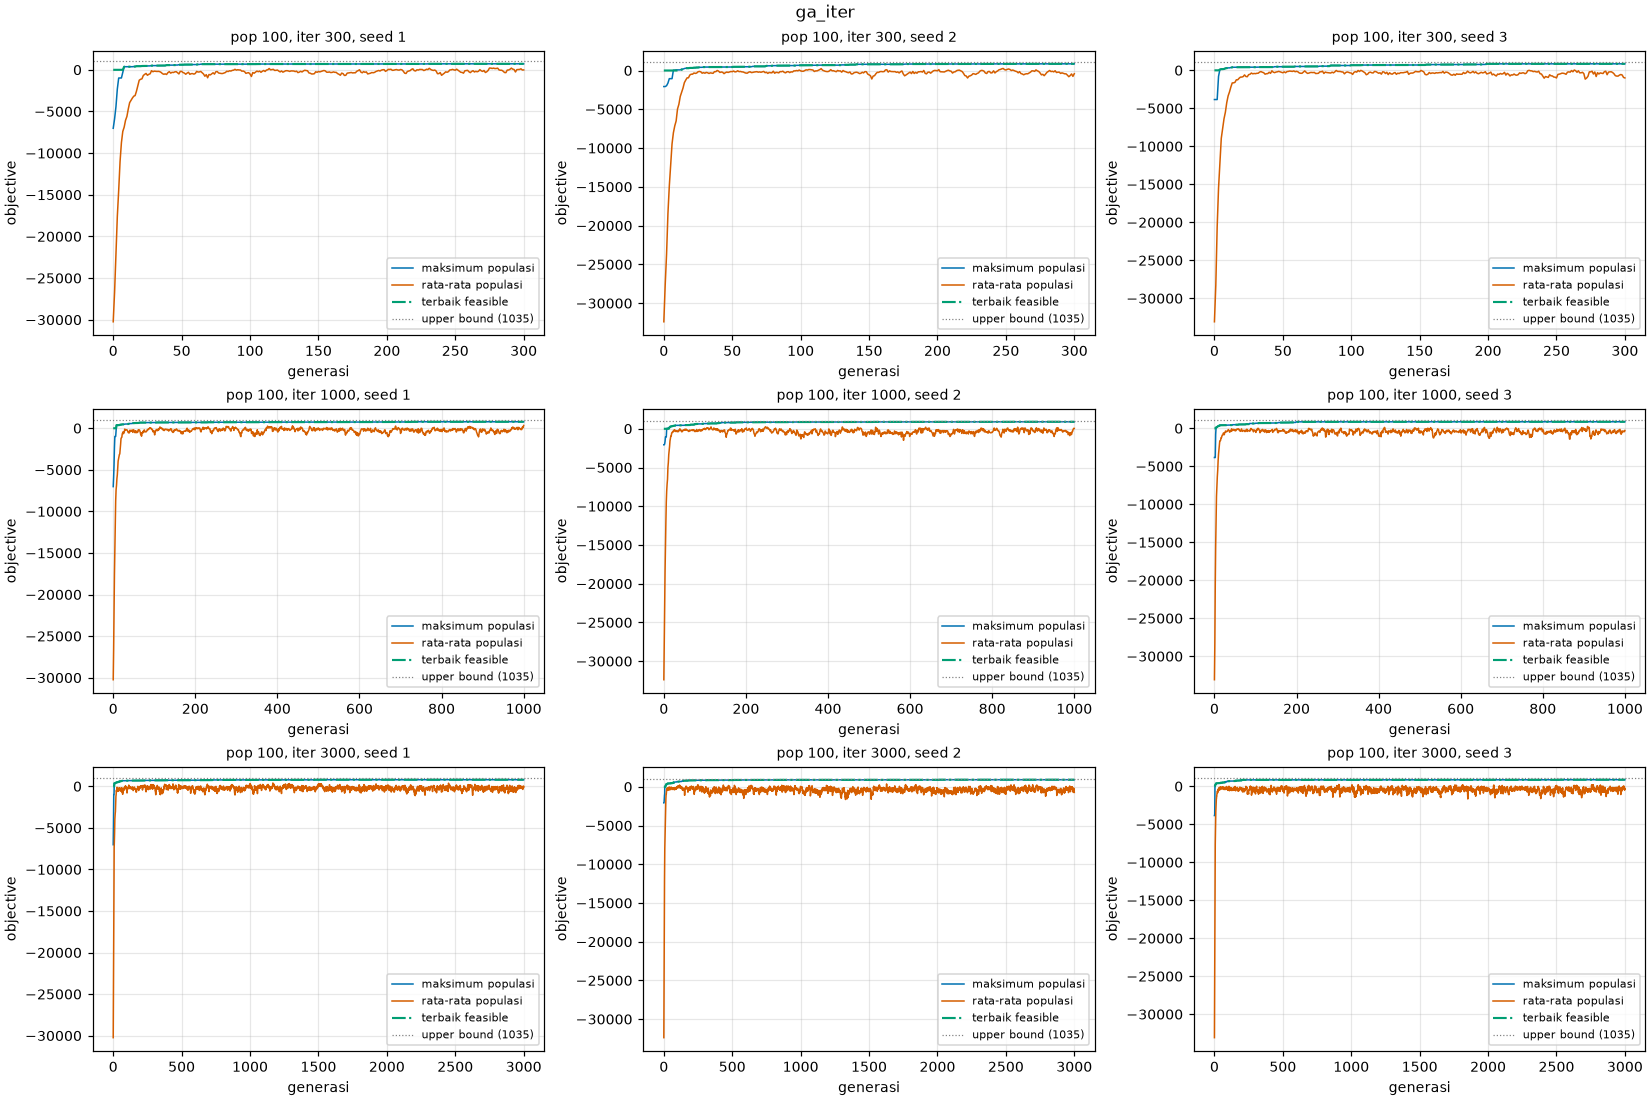

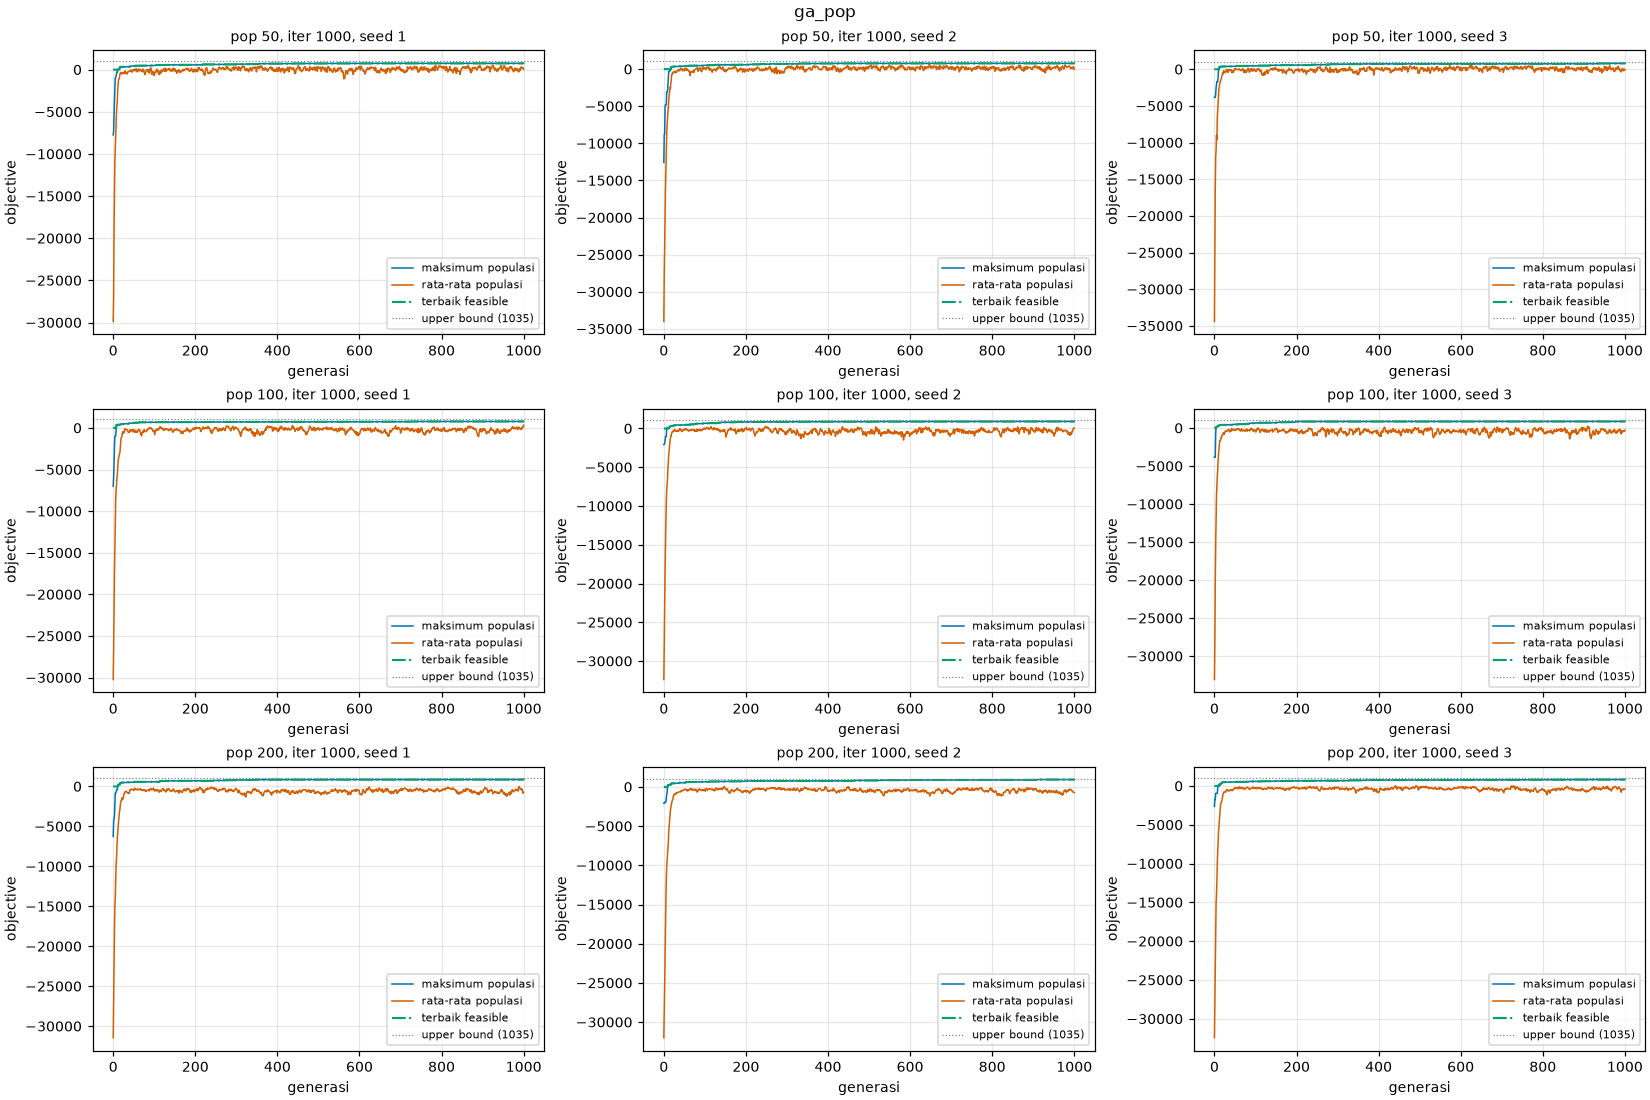

In [10]:
for group in ('ga_iter', 'ga_pop'):
    fig = Figure(figsize=(15, 10), layout='constrained')
    fig.suptitle(group)
    for ax, (run, result) in zip(fig.subplots(3, 3).flat, of(group)):
        plot_objective(ax, result)
        ax.set_title(f"pop {result['params']['population']}, iter {result['params']['iterations']}, seed {run.seed}", fontsize=9)
    show(fig)

In [11]:
ga_budget_rows = []
for group, key in (('ga_iter', 'iterations'), ('ga_pop', 'population')):
    members = of(group)
    for value in sorted({r['params'][key] for run, r in members}):
        selected = [r for run, r in members if r['params'][key] == value]
        ga_budget_rows.append([group, value, mean(r['final_objective'] for r in selected),
                               stdev(r['final_objective'] for r in selected),
                               mean(r['duration_s'] for r in selected), mean(r['evaluations'] for r in selected)])
table(['Sweep', 'Nilai parameter', 'Obj mean', 'Obj std', 'Durasi mean (s)', 'Evaluasi mean'],
      [[*row[:2], *(f'{v:.3f}' for v in row[2:])] for row in ga_budget_rows])
for group in ('ga_iter', 'ga_pop'):
    rows = [row for row in ga_budget_rows if row[0] == group]
    low, high = rows[0], rows[-1]
    insights(f'{group}: dari {low[1]} ke {high[1]}, perubahan mean objective = {high[2] - low[2]:+.2f}, '
             f'durasi = {high[4] - low[4]:+.3f} s, evaluasi = {high[5] - low[5]:+.0f}. '
             'Angka ini membandingkan budget aktual pada sweep tersebut; tidak menyatakan hubungan kausal universal.')

Sweep | Nilai parameter | Obj mean | Obj std | Durasi mean (s) | Evaluasi mean
--- | --- | --- | --- | --- | ---
ga_iter | 300 | 814.000 | 80.579 | 0.268 | 29500.000
ga_iter | 1000 | 851.000 | 65.138 | 0.805 | 98100.000
ga_iter | 3000 | 868.667 | 62.324 | 2.414 | 294100.000
ga_pop | 50 | 777.000 | 27.514 | 0.338 | 48050.000
ga_pop | 100 | 851.000 | 65.138 | 0.835 | 98100.000
ga_pop | 200 | 875.333 | 58.526 | 2.002 | 198200.000

#### Insights

> ga_iter: dari 300 ke 3000, perubahan mean objective = +54.67, durasi = +2.146 s, evaluasi = +264600. Angka ini membandingkan budget aktual pada sweep tersebut; tidak menyatakan hubungan kausal universal.

#### Insights

> ga_pop: dari 50 ke 200, perubahan mean objective = +98.33, durasi = +1.665 s, evaluasi = +150150. Angka ini membandingkan budget aktual pada sweep tersebut; tidak menyatakan hubungan kausal universal.

#### Insights

> Populasi dan generasi sama-sama memengaruhi jumlah evaluasi, sehingga kualitas perlu dibaca bersama biaya aktual. Kenaikan parameter tidak otomatis menjamin kenaikan kualitas pada setiap seed; kontrol kedua sweep tetap tersimpan terpisah.

---

# Perbandingan Algoritma <a name="8"></a>

---

Perbandingan hanya mencakup objective fee pada instance utama. GA diwakili konfigurasi dengan mean terbaik yang dipilih dari sweep yang sama; pemilihan ini bersifat deskriptif dan berpotensi optimistis, bukan evaluasi pada data uji terpisah.

Algoritma | n | Best | Mean | Std | Durasi (s) | Evaluasi | Gap UB (%)
--- | --- | --- | --- | --- | --- | --- | ---
steepest | 3 | 982.000 | 954.000 | 45.078 | 1.376 | 229241.333 | 7.826
sa | 3 | 973.000 | 966.333 | 5.859 | 9.015 | 1136824.000 | 6.634
stochastic | 3 | 876.000 | 808.333 | 58.705 | 0.349 | 31167.667 | 21.900
sideways | 3 | 982.000 | 973.333 | 11.719 | 10.523 | 1454800.000 | 5.958
random_restart | 3 | 993.000 | 973.667 | 24.583 | 16.745 | 2534384.667 | 5.926
ga (pop 200, iter 1000) - terbaik | 3 | 940.000 | 875.333 | 58.526 | 2.002 | 198200.000 | 15.427

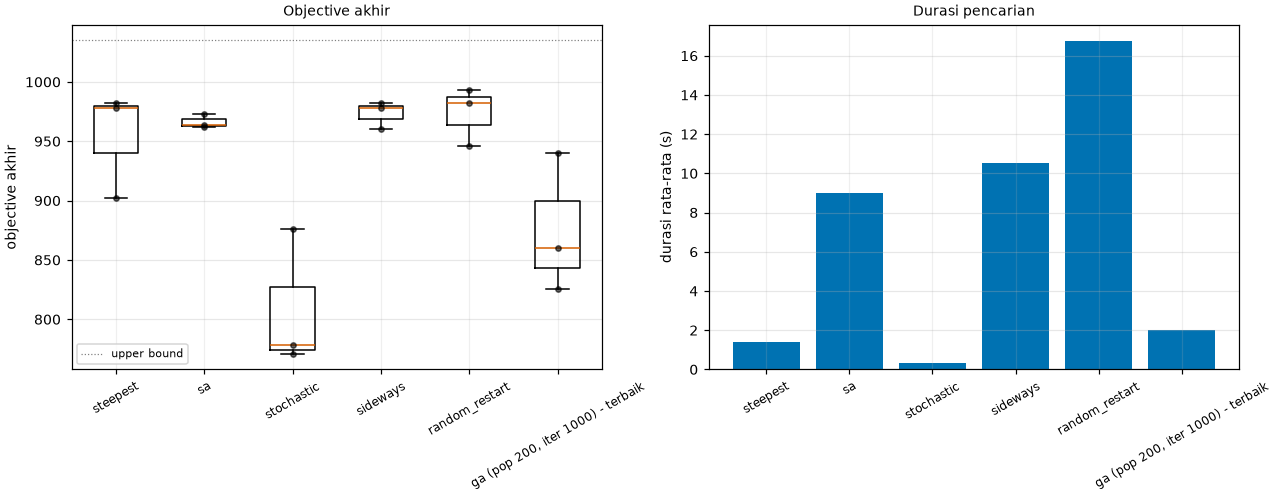

#### Insights

> Mean kualitas tertinggi: random_restart (973.67); durasi mean terendah: stochastic (0.349 s); simpangan baku terendah: sa (5.86). Jika terjadi seri, urutan tabel menentukan nama yang ditampilkan. Variansi kecil pada nilai rendah tidak berarti solusi berkualitas tinggi.

In [12]:
compare = comparison_groups(pairs)
comparison = []
for label, results in compare.items():
    finals = [r['final_objective'] for r in results]
    comparison.append([label, len(results), max(finals), mean(finals), stdev(finals) if len(finals) > 1 else 0,
                       mean(r['duration_s'] for r in results), mean(r['evaluations'] for r in results),
                       100 * mean(r['gap_ub'] for r in results)])
table(['Algoritma', 'n', 'Best', 'Mean', 'Std', 'Durasi (s)', 'Evaluasi', 'Gap UB (%)'],
      [[row[0], row[1], *(f'{v:.3f}' for v in row[2:])] for row in comparison])
labels = {id(r): label for label, results in compare.items() for r in results}
show(plot_summary([r for results in compare.values() for r in results], group=lambda r: labels[id(r)]))
best_quality = max(comparison, key=lambda row: row[3])
fastest = min(comparison, key=lambda row: row[5])
consistent = min(comparison, key=lambda row: row[4])
insights(f'Mean kualitas tertinggi: {best_quality[0]} ({best_quality[3]:.2f}); '
         f'durasi mean terendah: {fastest[0]} ({fastest[5]:.3f} s); '
         f'simpangan baku terendah: {consistent[0]} ({consistent[4]:.2f}). '
         'Jika terjadi seri, urutan tabel menentukan nama yang ditampilkan. '
         'Variansi kecil pada nilai rendah tidak berarti solusi berkualitas tinggi.')

## Biaya Evaluasi Aktual

Sumbu biaya menggunakan penghitung kumulatif `history.evaluations`, bukan interpolasi dari total evaluasi. Garis bertangga menahan incumbent pada evaluasi terakhir yang tercatat, tanpa mengarang peningkatan di antara dua observasi.

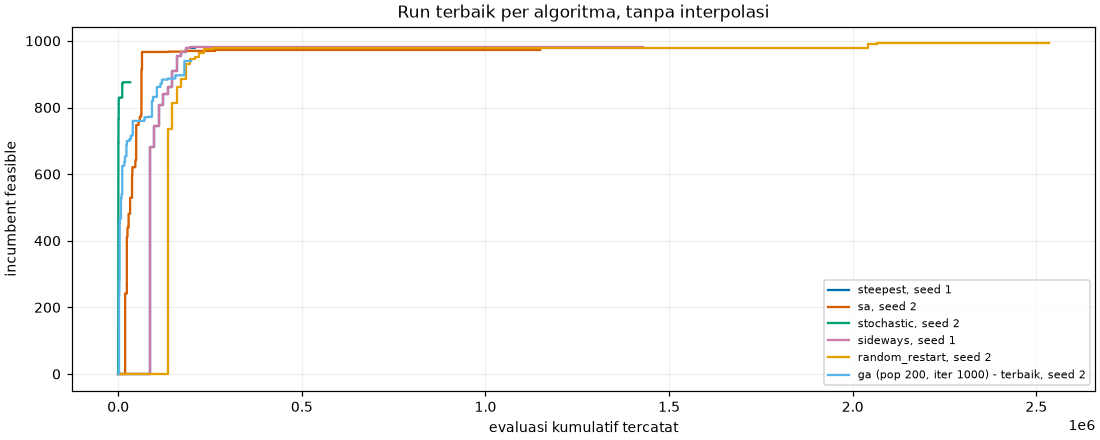

In [13]:
fig = Figure(figsize=(10, 4), layout='constrained')
ax = fig.subplots()
omitted = []
for label, results in compare.items():
    result = max(results, key=lambda r: r['final_objective'])
    history = result['history']
    x = history.get('evaluations')
    y = history.get('best_feasible')
    if x is None or y is None or len(x) != len(y):
        omitted.append(label)
        continue
    assert all(b >= a for a, b in zip(x, x[1:]))
    assert x[-1] <= result['evaluations']
    ax.step(x, y, where='post', label=f"{label}, seed {result['seed']}")
ax.set(xlabel='evaluasi kumulatif tercatat', ylabel='incumbent feasible', title='Run terbaik per algoritma, tanpa interpolasi')
if ax.lines:
    ax.legend(fontsize=7)
    show(fig)
else:
    print('Kurva evaluasi dihilangkan: tidak ada history evaluasi yang selaras.')
if omitted:
    print('Kurva dihilangkan karena history evaluasi/incumbent tidak tersedia atau tidak selaras:', ', '.join(omitted))

#### Insights

> Ranking kualitas, kecepatan, dan konsistensi menjawab pertanyaan berbeda. Plot biaya memakai satu run terbaik per algoritma untuk demo, sedangkan tabel tetap merangkum semua seed; biaya evaluasi juga tidak identik dengan waktu CPU per evaluasi.

---

# State Terbaik <a name="9"></a>

---

Untuk setiap algoritma pada perbandingan, state awal dan akhir dari run dengan objective akhir tertinggi digambar langsung dari JSON. Pemilihan memakai nilai akhir, bukan maksimum kurva yang mungkin masih melanggar kendala.

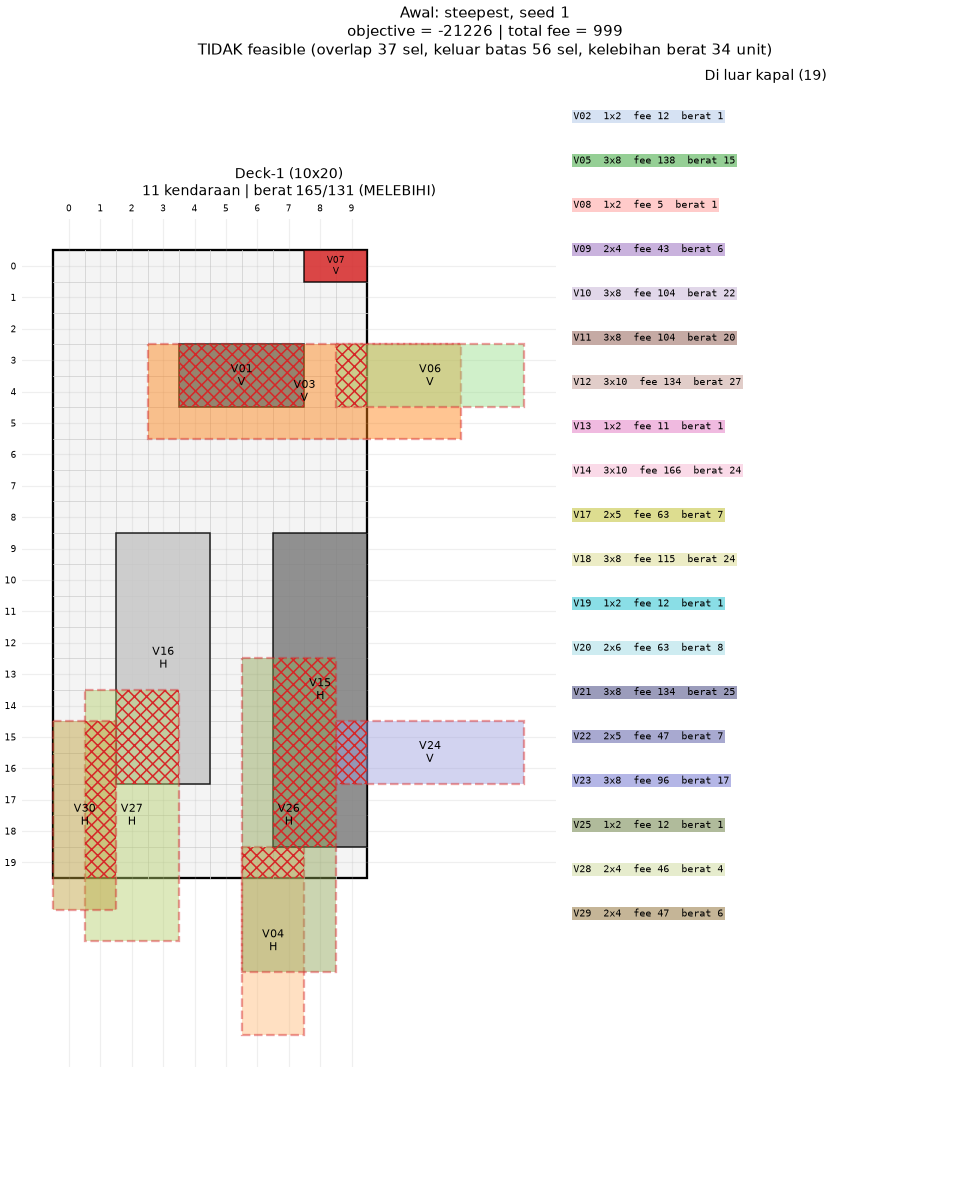

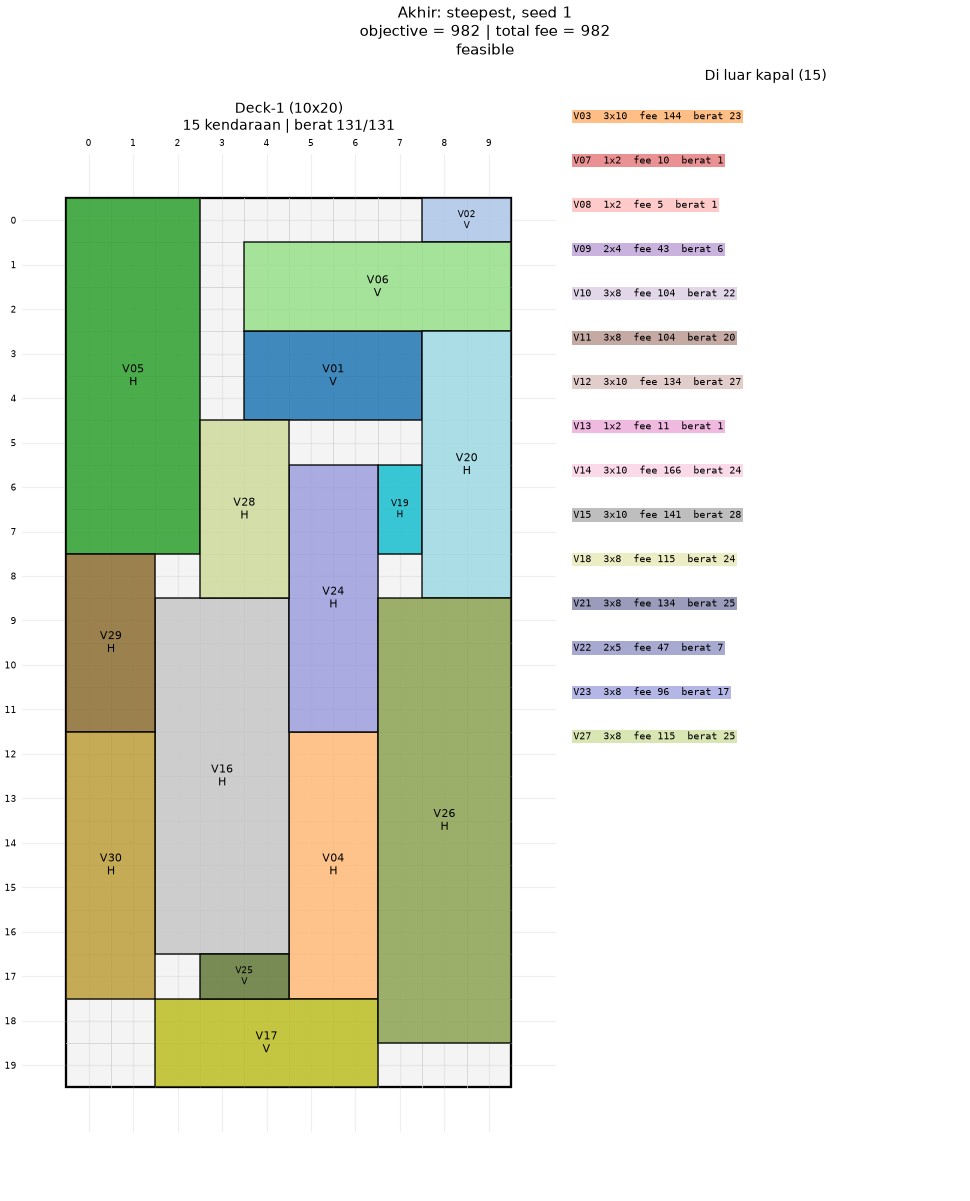

steepest | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 982.0


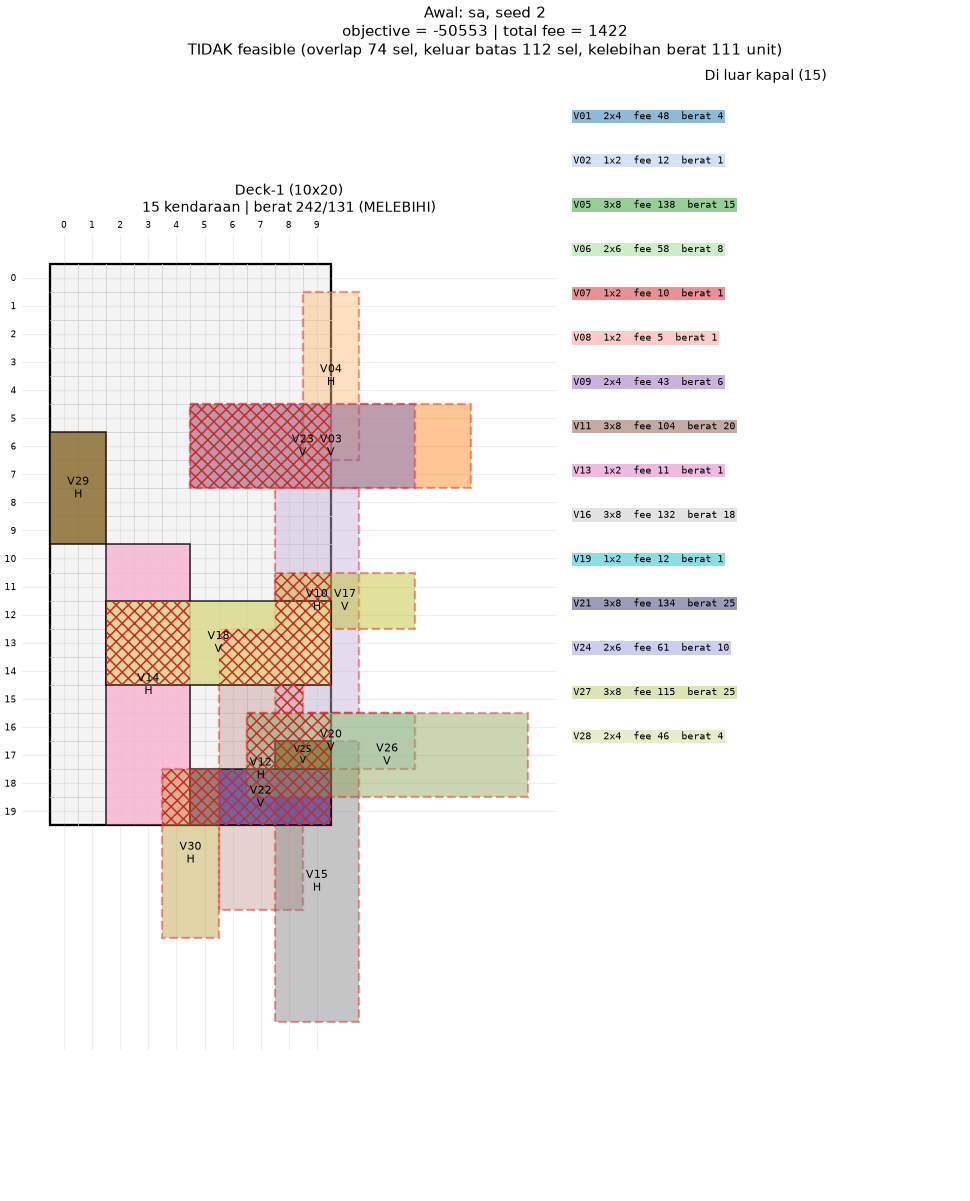

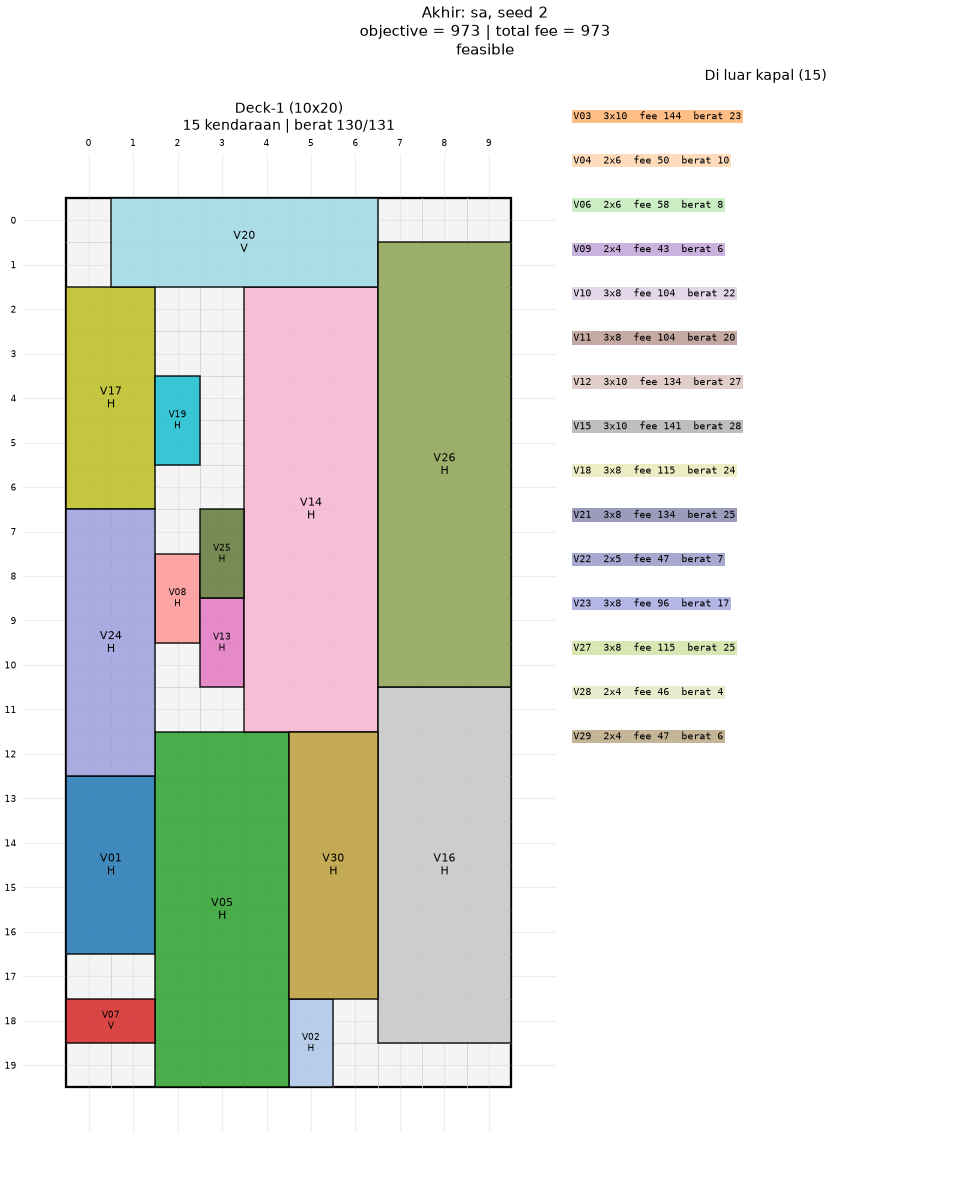

sa | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 973.0


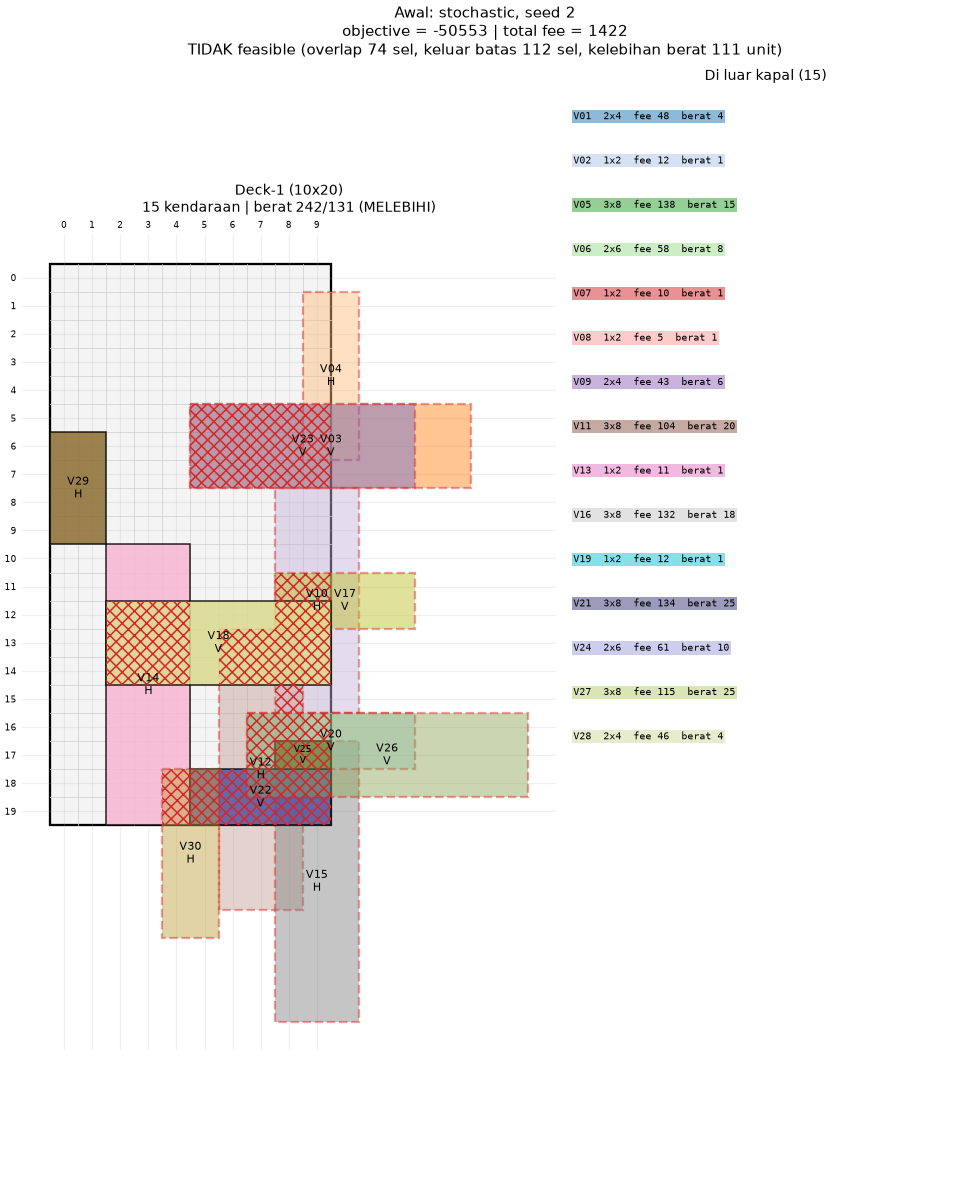

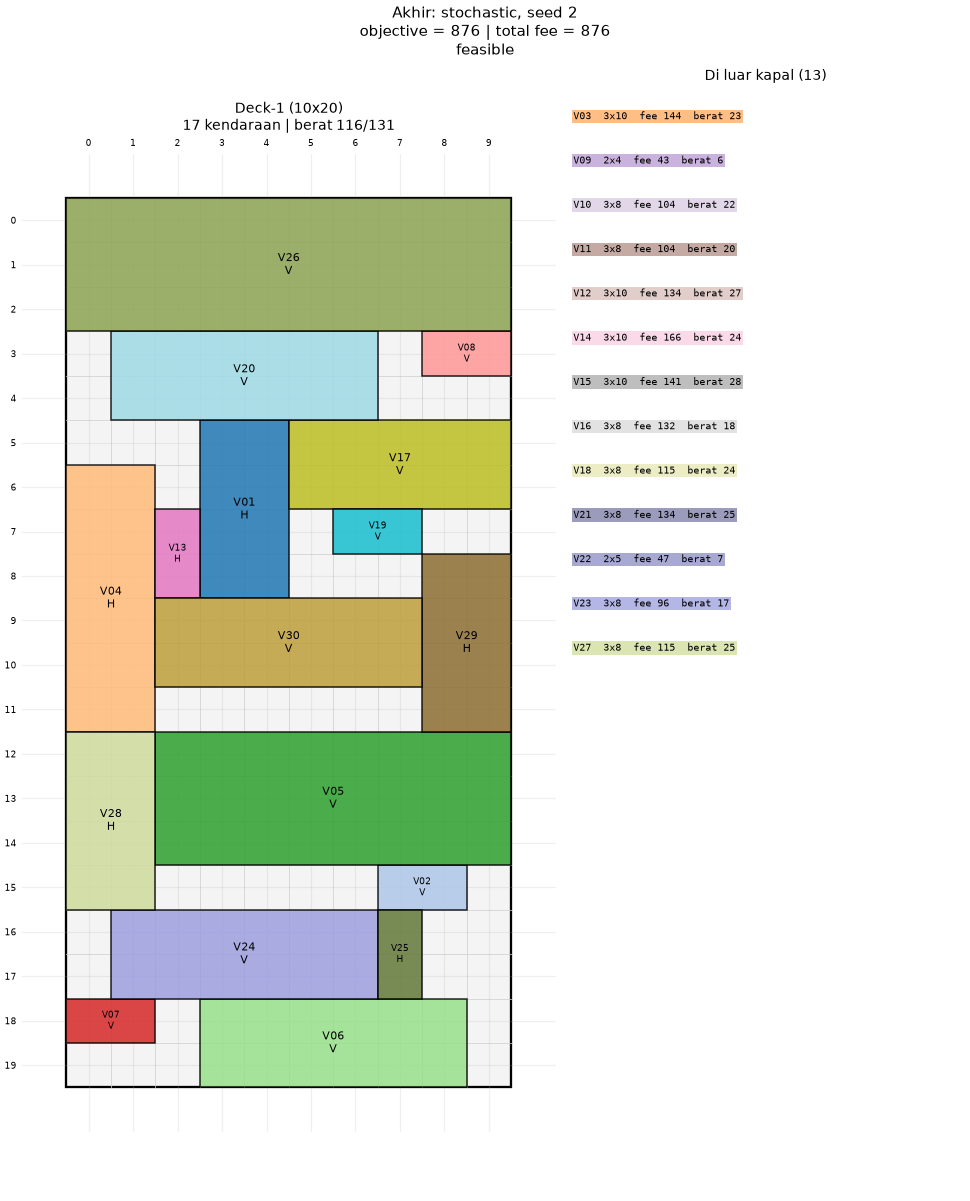

stochastic | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 876.0


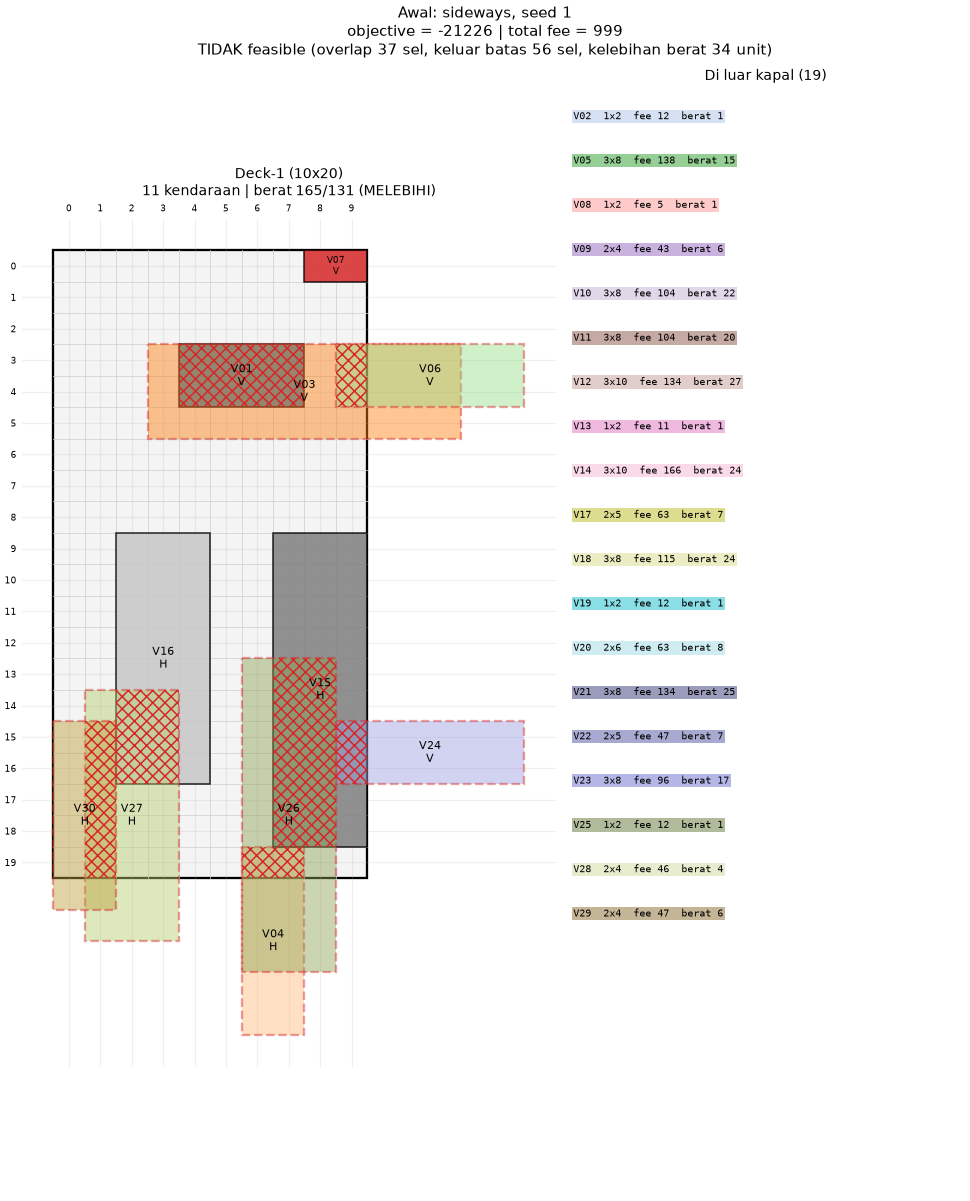

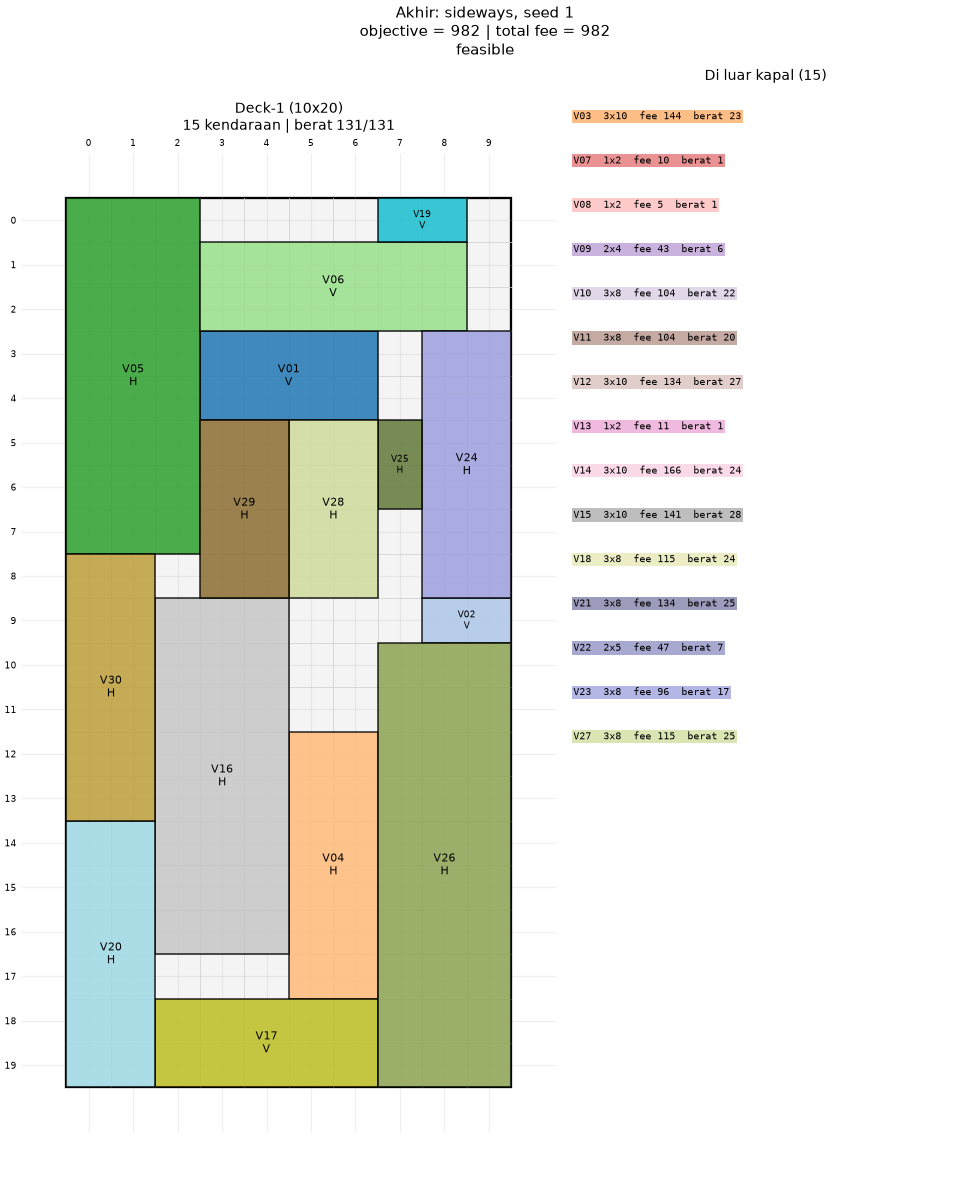

sideways | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 982.0


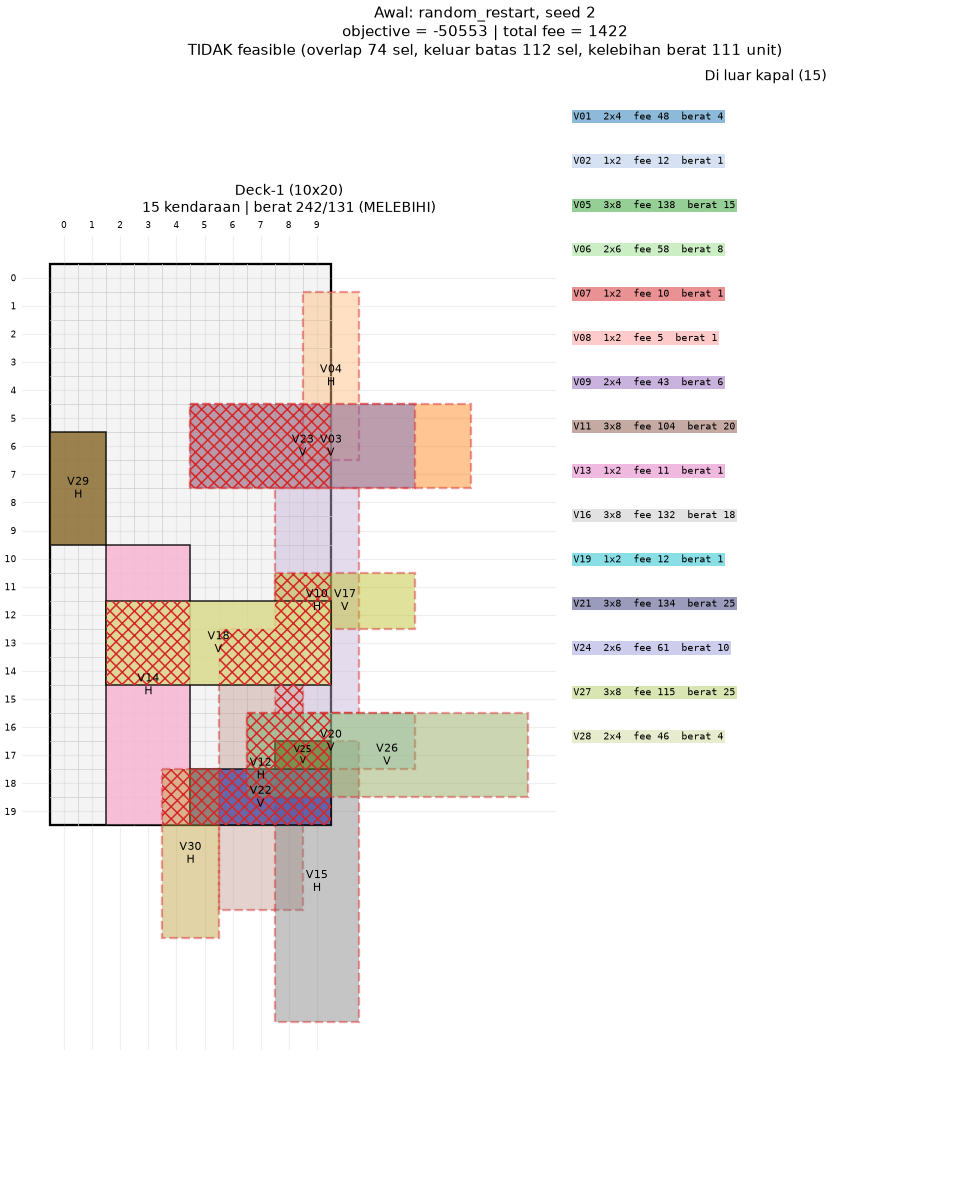

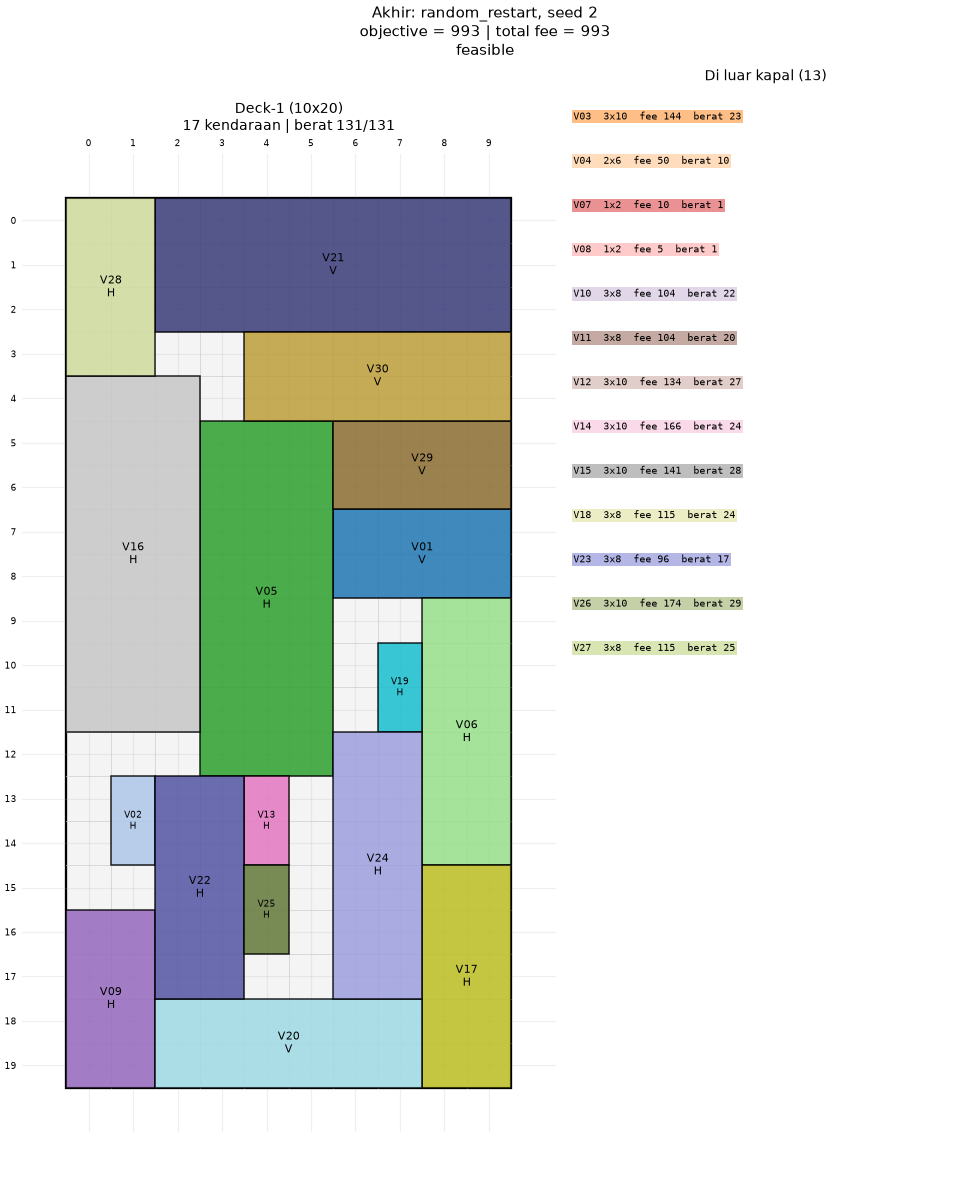

random_restart | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 837.0


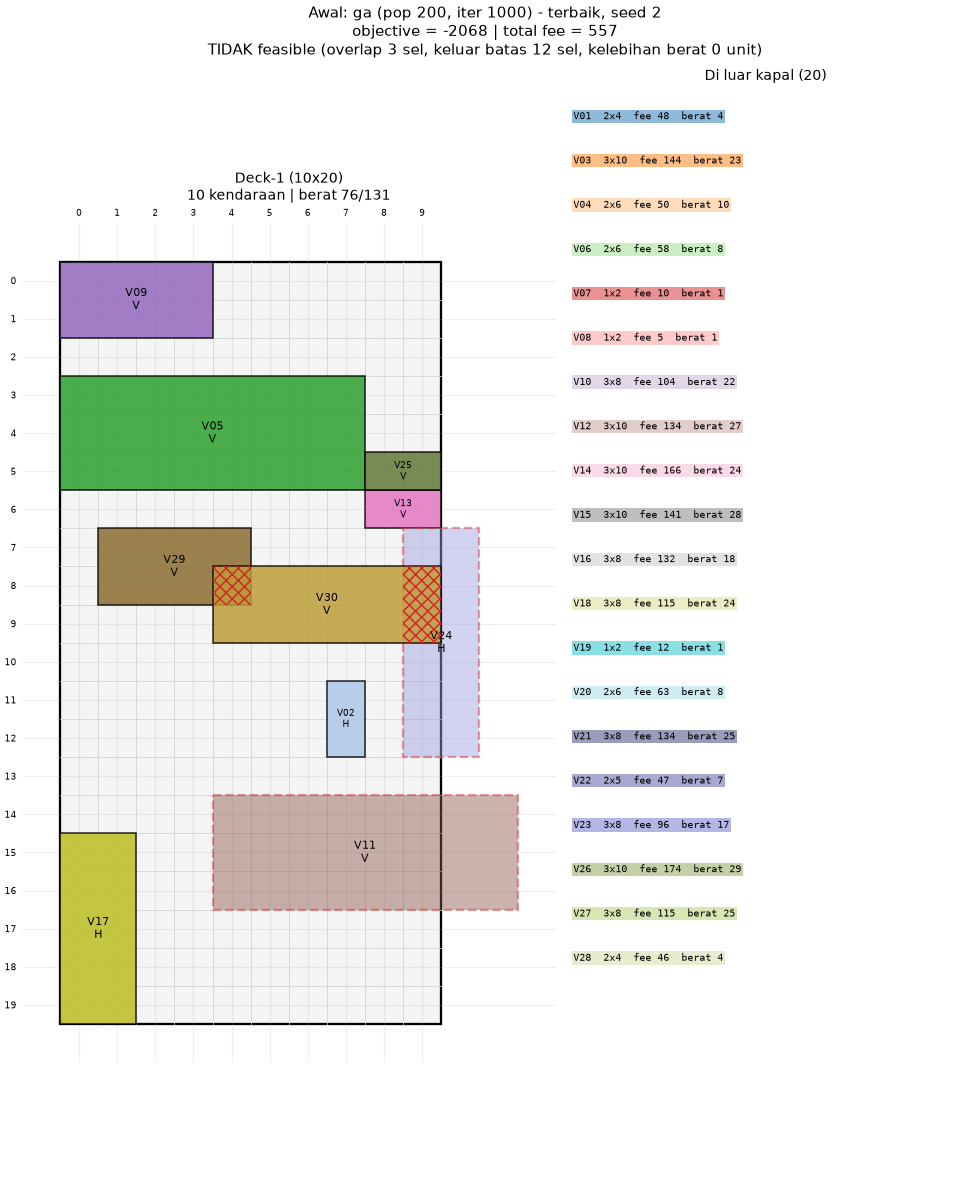

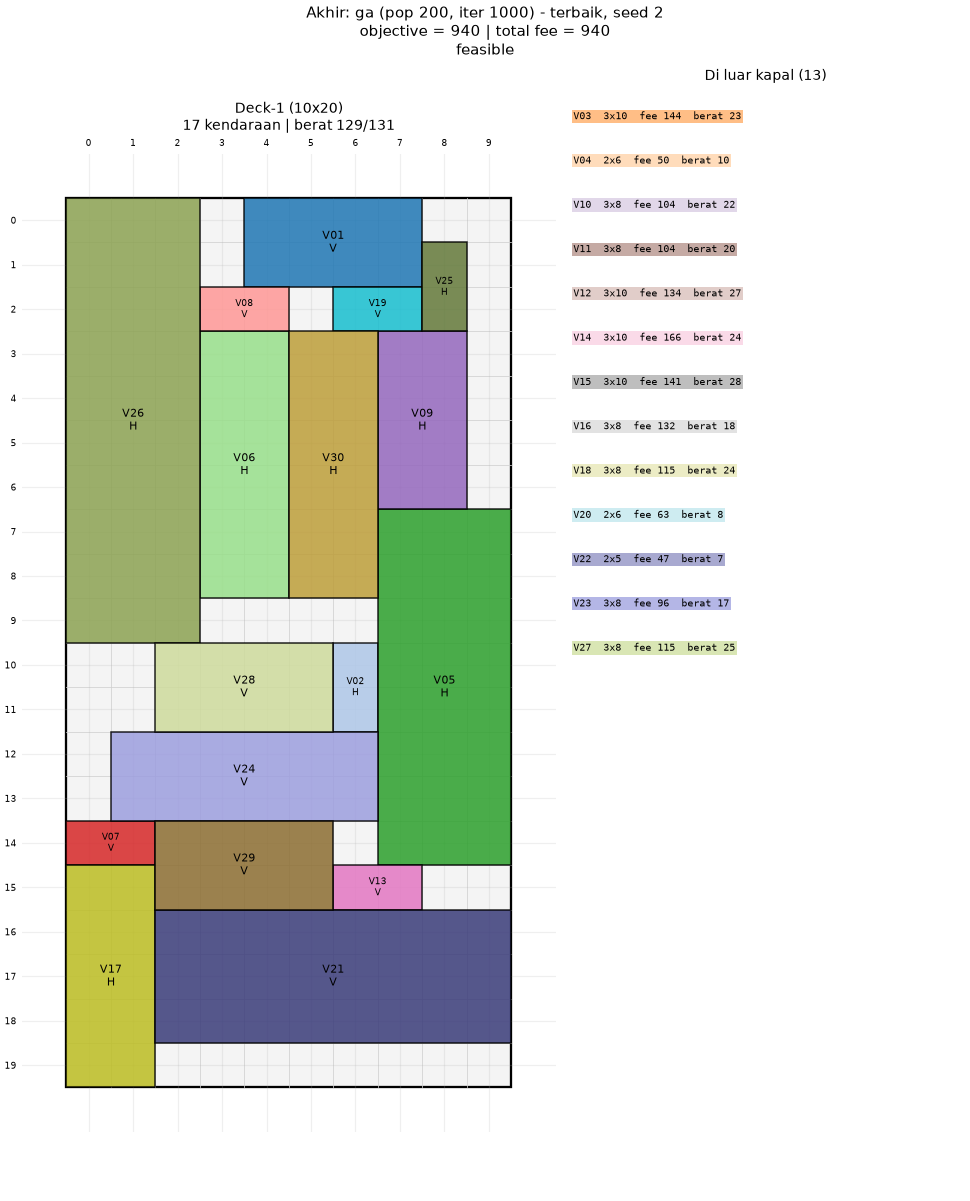

ga (pop 200, iter 1000) - terbaik | baseline kosong: False | kandidat feasible ditemukan: True | objective endpoint mentah: 940.0


In [14]:
for label, results in compare.items():
    best = max(results, key=lambda r: r['final_objective'])
    run = next(run for run, result in pairs if result is best)
    problem = problems[run.instance]
    for key, title in (('initial_state', 'Awal'), ('final_state', 'Akhir')):
        show(draw_state(problem, best[key], title=f"{title}: {label}, seed {best['seed']}"))
    print(label, '| baseline kosong:', best['extra'].get('empty_baseline_used', False),
          '| kandidat feasible ditemukan:', best['extra'].get('found_feasible', 'tidak dicatat'),
          '| objective endpoint mentah:', best['extra'].get('raw_final_objective', 'tidak dicatat'))

#### Insights

> Warna mengidentifikasi kendaraan secara konsisten; panel luar kapal tetap memperlihatkan kendaraan yang tidak diangkut. Arsir dan batas merah pada state awal memperlihatkan pelanggaran, bukan kerusakan gambar. Baseline kosong dinyatakan eksplisit dan tidak disamarkan sebagai keberhasilan menemukan muatan.

---

# Multi-kapal dan ETA <a name="10"></a>

---

## Multi-kapal

Penataan armada mengoptimalkan nilai total dengan kendala setiap kapal. Pemeriksaan berikut menampilkan penggunaan berat, luas, dan jumlah kendaraan per kapal pada run multi terbaik, tanpa menyamakan kapasitas gabungan dengan kebebasan menempatkan kendaraan di kapal mana pun.

Kapal | Kendaraan | Berat | Kapasitas | Sel terisi | Luas
--- | --- | --- | --- | --- | ---
Deck-1 | 10 | 70.0 | 80 | 96 | 120
Deck-2 | 6 | 51.0 | 54 | 64 | 80
Deck-3 | 5 | 30.0 | 32 | 44 | 48

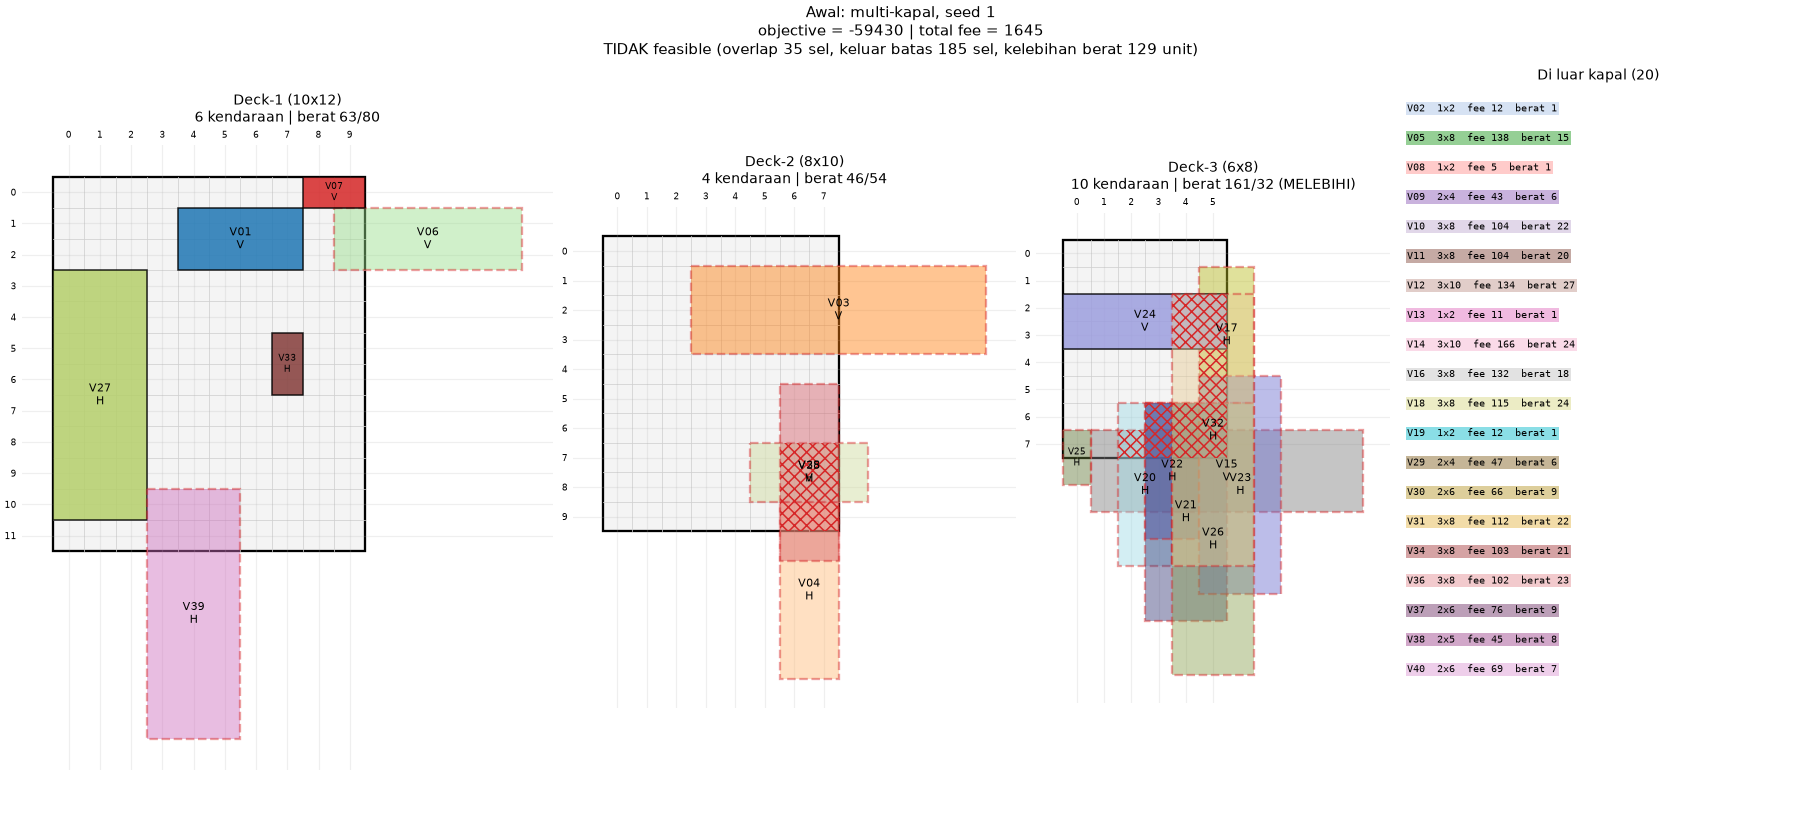

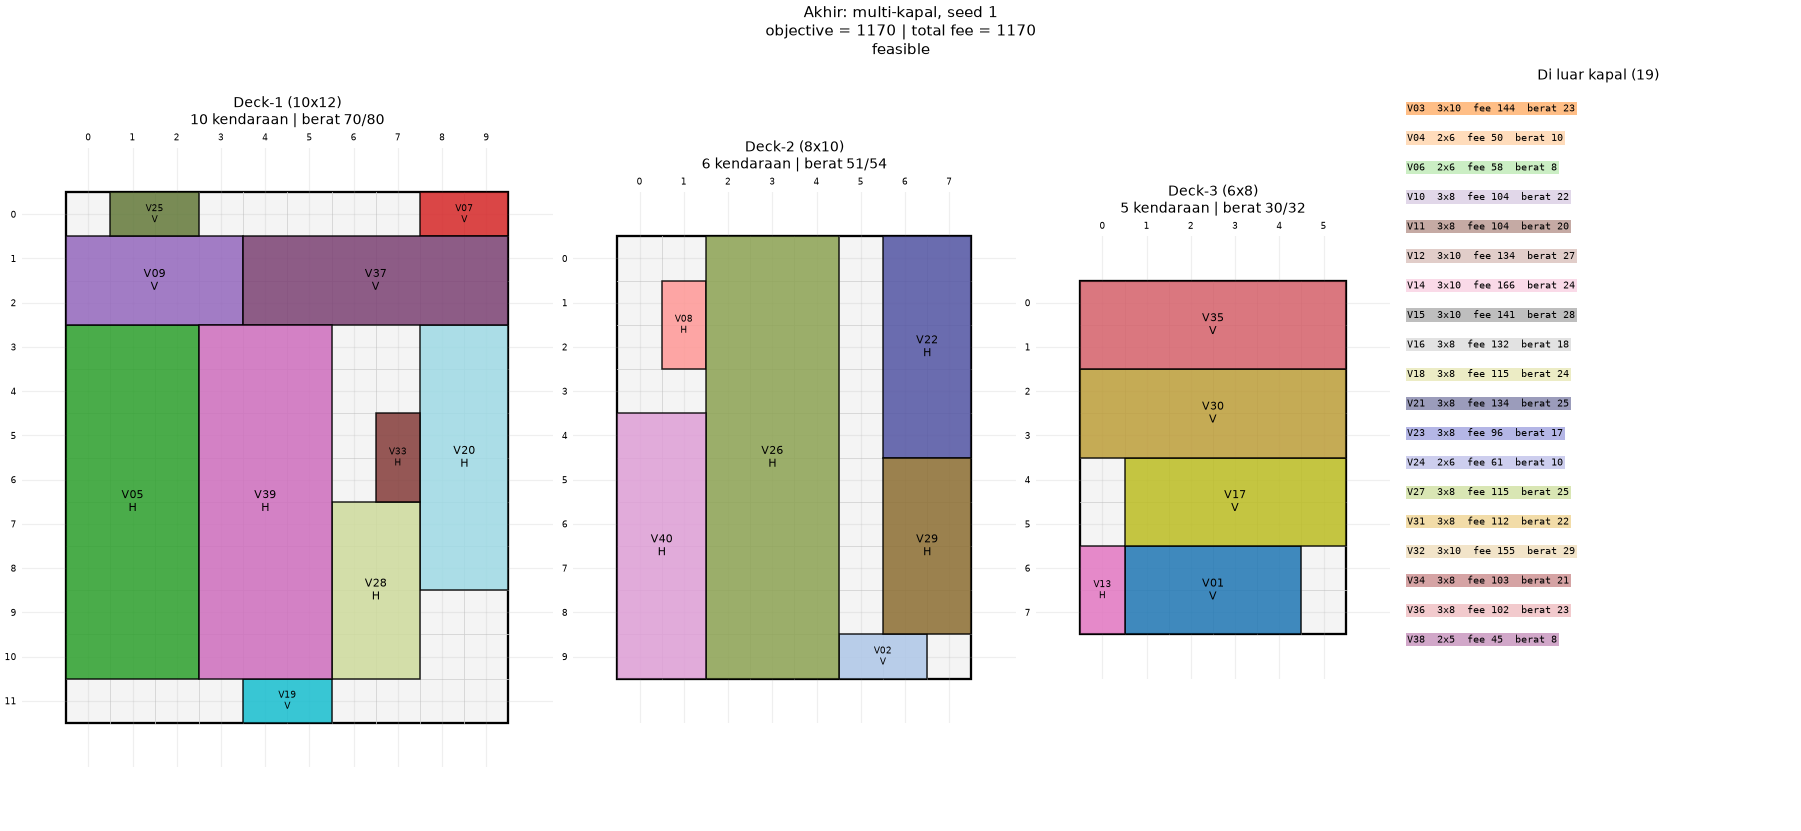

#### Insights

> Run multi terbaik memiliki objective 1170.00, memuat 21 kendaraan pada 3 kapal. Hasil tidak dibandingkan langsung dengan instance satu kapal karena data dan kapasitas berbeda.

In [15]:
multi_run, multi_best = max(of('multi'), key=lambda pair: pair[1]['final_objective'])
multi_problem = problems[multi_run.instance]
multi_state = State.from_dict(multi_problem, multi_best['final_state'])
evaluation = multi_state.evaluate()
table(['Kapal', 'Kendaraan', 'Berat', 'Kapasitas', 'Sel terisi', 'Luas'],
      [[ship.id, sum(p is not None and p[0] == i for p in multi_state.positions),
        evaluation.used_weight[i], ship.max_capacity, evaluation.occupied_cells[i], ship.area]
       for i, ship in enumerate(multi_problem.ships)])
for key, title in (('initial_state', 'Awal'), ('final_state', 'Akhir')):
    show(draw_state(multi_problem, multi_best[key], title=f'{title}: multi-kapal, seed {multi_run.seed}'))
insights(f"Run multi terbaik memiliki objective {multi_best['final_objective']:.2f}, "
         f"memuat {multi_best['loaded']} kendaraan pada {len(multi_problem.ships)} kapal. "
         'Hasil tidak dibandingkan langsung dengan instance satu kapal karena data dan kapasitas berbeda.')

#### Insights

> Feasibility dihitung per kapal, bukan hanya dari berat total armada. Satu kapal dapat menyisakan ruang karena bentuk kendaraan dan kapasitas berat; gambar saja tidak membuktikan penyebab spesifik suatu ruang kosong.

## Objective Urgensi ETA

Bobot alternatif adalah `fee * (1 + 1/(eta + 1))`. Bobot ini bukan uang dan tidak mengubah kapasitas fisik. Pasangan run fee dan ETA pada seed yang sama dinilai ulang dengan kedua metrik agar perbandingan tidak mencampurkan skala objective.

In [16]:
eta_rows = []
for eta_run, eta_result in of('eta'):
    original = problems[eta_run.instance]
    fee_run, fee_result = next((run, result) for run, result in of('sa') if run.seed == eta_run.seed)
    assert fee_run.instance == eta_run.instance
    assert fee_result['params'] == eta_result['params']
    for mode, result in (('fee', fee_result), ('eta', eta_result)):
        state = State.from_dict(original, result['final_state'])
        revenue = shipping_fee_total(original, state.positions)
        urgency = sum(urgency_weight(v) for v, p in zip(original.vehicles, state.positions) if p is not None)
        eta_rows.append([eta_run.seed, mode, revenue, urgency,
                         sum(p is not None for p in state.positions), result['duration_s']])
    fee_initial = State.from_dict(original, fee_result['initial_state']).positions
    eta_initial = State.from_dict(original, eta_result['initial_state']).positions
    assert fee_initial == eta_initial
table(['Seed', 'Objective pencarian', 'Fee asli', 'Bobot urgensi', 'Dimuat', 'Durasi (s)'],
      [[*row[:2], f'{row[2]:.2f}', f'{row[3]:.2f}', row[4], f'{row[5]:.3f}'] for row in eta_rows])
fee_mean = mean(row[2] for row in eta_rows if row[1] == 'fee')
eta_fee_mean = mean(row[2] for row in eta_rows if row[1] == 'eta')
fee_urgency = mean(row[3] for row in eta_rows if row[1] == 'fee')
eta_urgency = mean(row[3] for row in eta_rows if row[1] == 'eta')
insights(f'Perubahan mean ETA terhadap fee: pendapatan asli {eta_fee_mean - fee_mean:+.2f}; '
         f'bobot urgensi {eta_urgency - fee_urgency:+.2f}. '
         'Seed, parameter, dan penempatan awal berpasangan; hasil tetap merupakan sampel pencarian stokastik, '
         'bukan jaminan trade-off dengan arah yang sama pada semua instance.')

Seed | Objective pencarian | Fee asli | Bobot urgensi | Dimuat | Durasi (s)
--- | --- | --- | --- | --- | ---
1 | fee | 964.00 | 1243.45 | 11 | 8.435
1 | eta | 984.00 | 1293.30 | 16 | 8.455
2 | fee | 973.00 | 1206.80 | 15 | 8.488
2 | eta | 941.00 | 1223.58 | 16 | 8.808
3 | fee | 962.00 | 1148.13 | 17 | 10.121
3 | eta | 941.00 | 1228.80 | 15 | 8.883

#### Insights

> Perubahan mean ETA terhadap fee: pendapatan asli -11.00; bobot urgensi +49.10. Seed, parameter, dan penempatan awal berpasangan; hasil tetap merupakan sampel pencarian stokastik, bukan jaminan trade-off dengan arah yang sama pada semua instance.

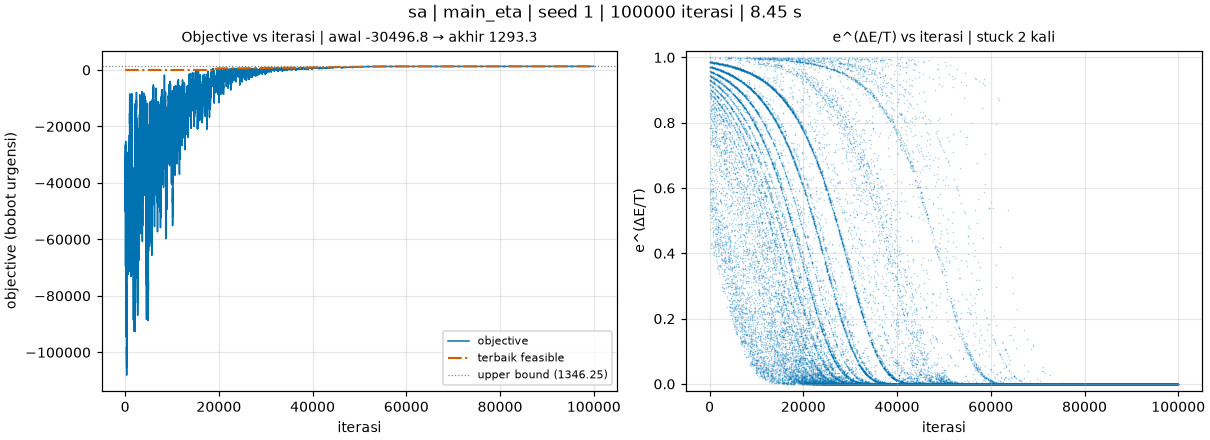

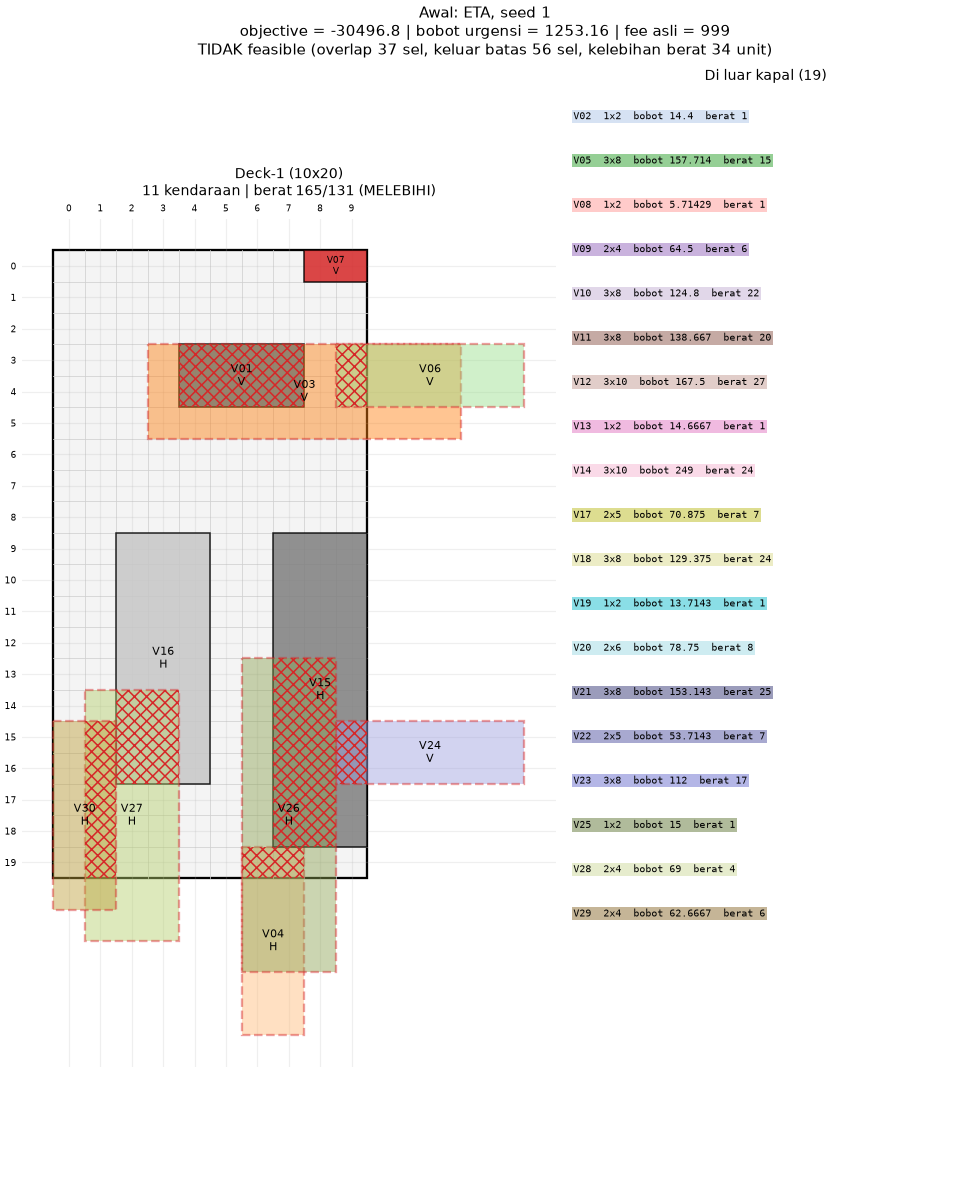

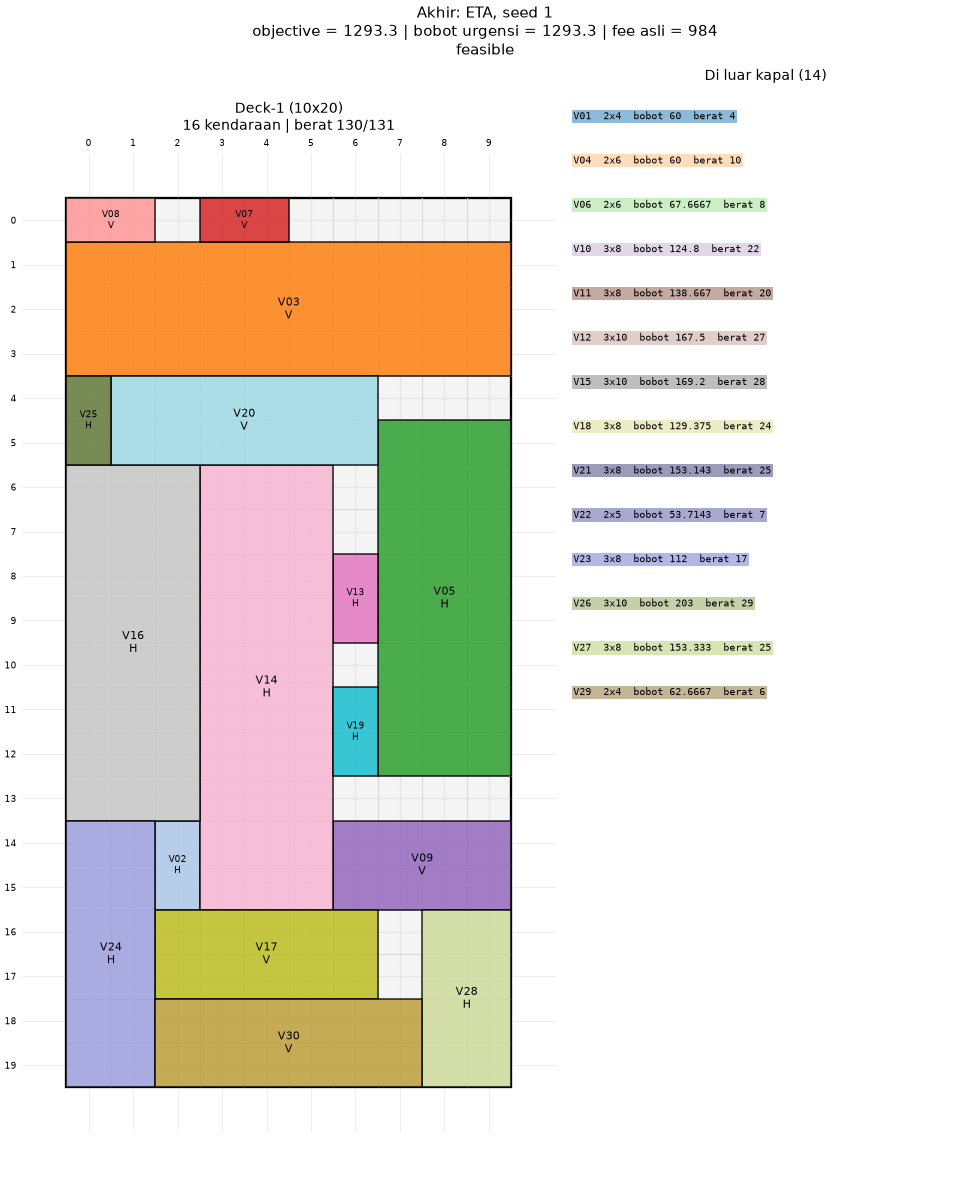

In [17]:
eta_run, eta_best = max(of('eta'), key=lambda pair: pair[1]['final_objective'])
transformed = eta_problem(problems[eta_run.instance])
show(plot_run(eta_best))
for key, title in (('initial_state', 'Awal'), ('final_state', 'Akhir')):
    original_state = State.from_dict(problems[eta_run.instance], eta_best[key])
    actual_fee = shipping_fee_total(problems[eta_run.instance], original_state.positions)
    show(draw_state(transformed, eta_best[key], title=f'{title}: ETA, seed {eta_run.seed}',
                    objective='eta', shipping_fee=actual_fee))

#### Insights

> `total_fee` dalam JSON ETA berisi total bobot transformasi; pendapatan moneternya berada pada `extra.shipping_fee_total`. Gambar dan tabel mempertahankan perbedaan ini, termasuk ketika kedua nilai kebetulan sama.

---

# Batas Atas dan Optimum Eksak <a name="11"></a>

---

Batas atas mengabaikan sebagian kendala geometri, sehingga nilainya minimal sebesar optimum feasible. Optimum eksak hanya dihitung untuk `small.json` dengan enumerasi branch-and-bound; hasil kecil tidak membuktikan optimalitas pada instance utama atau multi-kapal.

Instance | Optimum eksak | Upper bound | Kelonggaran UB
--- | --- | --- | ---
small | 287.0 | 298.0 | 11.0

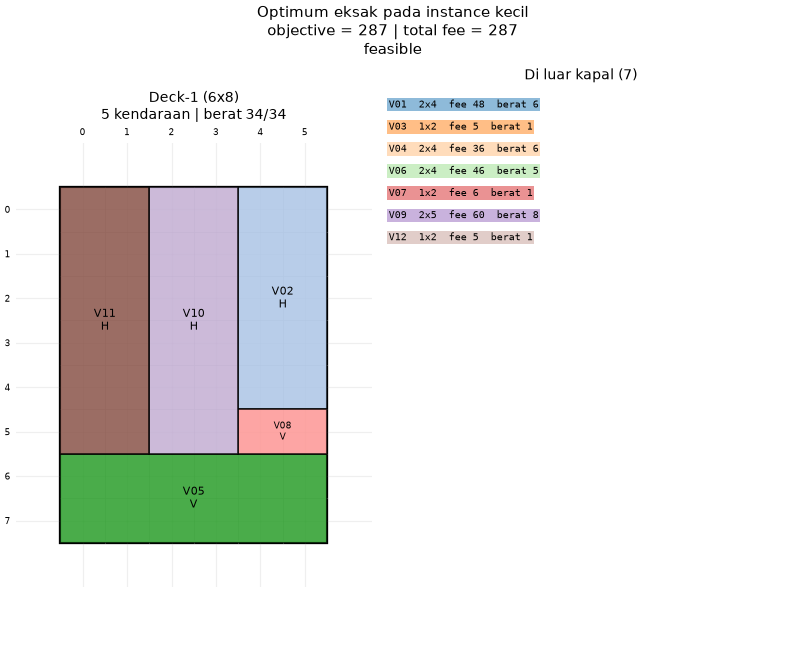

#### Insights

> Instance kecil: optimum eksak 287, UB 298. Instance utama: incumbent terbaik 993, UB 1035. Incumbent dan UB memberi interval optimum; selisihnya tidak membuktikan seberapa jauh solusi dari optimum geometris.

In [18]:
small = load_problem(CFG.DATA_DIR / 'small.json')
exact = brute_force(small, max_nodes=CFG.EXACT_MAX_NODES)
small_bound = upper_bound(small)
assert exact.evaluate().is_feasible
assert exact.objective <= small_bound + 1e-7
table(['Instance', 'Optimum eksak', 'Upper bound', 'Kelonggaran UB'],
      [[small.name, exact.objective, small_bound, small_bound - exact.objective]])
show(draw_state(small, exact.to_dict(), title='Optimum eksak pada instance kecil'))
main_bound = next(result['upper_bound'] for run, result in of('hc'))
best_main = max(result['final_objective'] for results in compare.values() for result in results)
insights(f'Instance kecil: optimum eksak {exact.objective:g}, UB {small_bound:g}. '
         f'Instance utama: incumbent terbaik {best_main:g}, UB {main_bound:g}. '
         + ('Kesamaan incumbent dan UB membuktikan optimum pada instance utama.'
            if math.isclose(best_main, main_bound, abs_tol=1e-7)
            else 'Incumbent dan UB memberi interval optimum; selisihnya tidak membuktikan seberapa jauh solusi dari optimum geometris.'))

#### Insights

> Jika solusi feasible mencapai UB yang valid, optimalitas terbukti untuk instance dan objective tersebut. Jika belum mencapai UB, penyebabnya dapat berupa relaksasi yang longgar, pencarian yang belum optimal, atau keduanya; hasil eksperimen ini tidak memisahkan penyebab tersebut.

---

# Kesimpulan dan Referensi <a name="12"></a>

---

Ringkasan akhir menghitung jawaban atas kualitas, durasi, konsistensi, budget GA, dan indikator SA dari artefak yang telah diperiksa. Semua rekomendasi dibatasi pada instance serta seed dalam protokol ini.

In [19]:
insights(f"Pada {len(pairs)} run resmi, mean kualitas tertinggi pada perbandingan adalah {best_quality[0]}; "
         f"durasi mean terendah adalah {fastest[0]}; simpangan baku terendah adalah {consistent[0]}. "
         f"Rata-rata episode stuck checkpoint SA adalah {mean(r['extra']['stuck_count'] for r in sa_results):.2f}. "
         'Tabel GA menunjukkan biaya evaluasi dan perubahan kualitas untuk kedua sumbu budget. '
         'Pernyataan ini merangkum pengamatan, bukan klaim dominasi algoritma secara umum.')

#### Insights

> Pada 39 run resmi, mean kualitas tertinggi pada perbandingan adalah random_restart; durasi mean terendah adalah stochastic; simpangan baku terendah adalah sa. Rata-rata episode stuck checkpoint SA adalah 2.67. Tabel GA menunjukkan biaya evaluasi dan perubahan kualitas untuk kedua sumbu budget. Pernyataan ini merangkum pengamatan, bukan klaim dominasi algoritma secara umum.

#### Insights

> Reproduksi analisis memerlukan data, konfigurasi, seluruh JSON, dan gambar dari run resmi yang sama. Pengulangan analisis tidak mengulangi search; perubahan algoritma atau parameter memerlukan regenerasi eksperimen sebelum simpulan baru diambil.

## Referensi

Spesifikasi: `docs/Spesifikasi Tugas Besar 1 IF3070 Dasar Inteligensi Artifisial 2026_2027.md`, bagian Cakupan dan Bonus. Implementasi dan protokol: `docs/DESIGN.md`, `docs/EXPERIMENTS.md`, serta `src/search/` dan `src/core/`.

Materi IF3070 oleh M. L. Khodra: [Hill-Climbing](https://www.youtube.com/watch?v=L0b0CN3Fds8), [Simulated Annealing](https://www.youtube.com/watch?v=AdhG7HnhYrk), dan [Genetic Algorithm](https://www.youtube.com/watch?v=aI41TGo9J9c). Referensi materi lengkap mengikuti dokumen spesifikasi; kode analisis menggunakan implementasi lokal repository.